<a href="https://colab.research.google.com/github/Shivdums/Benchmarking-AutoDock-Vina-against-alternative-scoring-functions-and-AlphaFold-ensembles-on-LIT-PCBA/blob/main/docking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!wget -q https://github.com/ccsb-scripps/AutoDock-Vina/releases/download/v1.2.5/vina_1.2.5_linux_x86_64 -O /usr/local/bin/vina
!chmod +x /usr/local/bin/vina
!vina --version

AutoDock Vina v1.2.5


In [ ]:
# ── SETUP ─────────────────────────────────────────────────────────────
!pip -q install rdkit meeko py3Dmol tqdm scikit-learn seaborn
!apt-get -qq install -y openbabel > /dev/null

!wget -q https://github.com/ccsb-scripps/AutoDock-Vina/releases/download/v1.2.5/vina_1.2.5_linux_x86_64 -O /usr/local/bin/vina
!chmod +x /usr/local/bin/vina

from google.colab import drive
drive.mount('/content/drive')
PROJ = '/content/drive/MyDrive/docking_project'
!mkdir -p {PROJ}

import rdkit; print('rdkit', rdkit.__version__)
!obabel -V
!vina --version
!nvidia-smi --query-gpu=name --format=csv,noheader

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
rdkit 2026.09.1
Open Babel 3.1.1 -- Mar 31 2024 -- 06:39:03
AutoDock Vina v1.2.5
Tesla T4


In [ ]:
!curl -sSI -m 20 https://lsd.docking.org/ | head -3

curl: (28) Connection timed out after 20002 milliseconds


In [ ]:
!nslookup lsd.docking.org | tail -4
!for h in lsd wiki files zinc20; do echo -n "$h: "; curl -sS -m 10 -o /dev/null -w "%{http_code}\n" -A "Mozilla/5.0" https://$h.docking.org/ 2>&1 | tail -1; done

Non-authoritative answer:
Name:	lsd.docking.org
Address: 169.230.75.4

lsd: 000
wiki: 000
files: 000
zinc20: 302


In [ ]:
!wget -c http://drugdesign.unistra.fr/downloads/datasets/LIT-PCBA_full.tar.gz
!tar xzf LIT-PCBA_full.tar.gz

--2026-11-05 23:47:38--  http://drugdesign.unistra.fr/downloads/datasets/LIT-PCBA_full.tar.gz
Resolving drugdesign.unistra.fr (drugdesign.unistra.fr)... 130.79.214.123
Connecting to drugdesign.unistra.fr (drugdesign.unistra.fr)|130.79.214.123|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://lab.drugdesign.unistra.fr/downloads/datasets/LIT-PCBA_full.tar.gz [following]
--2026-11-05 23:47:39--  https://lab.drugdesign.unistra.fr/downloads/datasets/LIT-PCBA_full.tar.gz
Resolving lab.drugdesign.unistra.fr (lab.drugdesign.unistra.fr)... 130.79.214.123
Connecting to lab.drugdesign.unistra.fr (lab.drugdesign.unistra.fr)|130.79.214.123|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-05 23:47:40 ERROR 404: Not Found.

tar (child): LIT-PCBA_full.tar.gz: Cannot open: No such file or directory
tar (child): Error is not recoverable: exiting now
tar: Child returned status 2
tar: Error is not recoverable: exiting now


In [ ]:
!wget -c https://lab.drugdesign.unistra.fr/downloads/datasets/LIT-PCBA_full.tar.gz

--2026-11-05 23:47:40--  https://lab.drugdesign.unistra.fr/downloads/datasets/LIT-PCBA_full.tar.gz
Resolving lab.drugdesign.unistra.fr (lab.drugdesign.unistra.fr)... 130.79.214.123
Connecting to lab.drugdesign.unistra.fr (lab.drugdesign.unistra.fr)|130.79.214.123|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-05 23:47:40 ERROR 404: Not Found.



In [ ]:
!pip -q install huggingface_hub
from huggingface_hub import list_repo_files, hf_hub_download


print([f for f in list_repo_files("SaeedLab/BindScreen", repo_type="dataset")
       if "lit" in f.lower()][:40])

['lit_pcba/test.parquet', 'lit_pcba/train.parquet', 'lit_pcba/valid.parquet']


In [ ]:
import pandas as pd
from huggingface_hub import hf_hub_download, HfApi

f = hf_hub_download("SaeedLab/BindScreen", "lit_pcba/train.parquet", repo_type="dataset")
df = pd.read_parquet(f)
print(df.shape)
print(df.columns.tolist())
display(df.head())

print("---- DrugCLIP repo ----")
for s in HfApi().list_repo_tree("THU-ATOM/DrugCLIP_data", repo_type="dataset"):
    print(s.path, getattr(s, "size", None))

lit_pcba/train.parquet: reconstructing file:   0%|          |  0.00B / 13.9MB            

lit_pcba/train.parquet: downloading bytes:           |  0.00B            

(548294, 5)
['prot_id', 'prot', 'mol_id', 'mol', 'active']


,prot_id,prot,mol_id,mol,active
0,P0A4L9,MTEEIKNLQAQDYDASQIQVLEGLEAVRMRPGMYIGSTSKEGLHHL...,CHEMBL36506,CO[C@@H]1[C@@H](OC(N)=O)[C@@H](O)[C@H](Oc2ccc3...,1
1,P0A4L9,MTEEIKNLQAQDYDASQIQVLEGLEAVRMRPGMYIGSTSKEGLHHL...,CHEMBL565572,CCNC(=O)Nc1cn2c(-c3ncc(C(F)(F)F)cn3)cc(-c3cccn...,1
2,P0A4L9,MTEEIKNLQAQDYDASQIQVLEGLEAVRMRPGMYIGSTSKEGLHHL...,CHEMBL565741,CCC(=O)Nc1cn2c(-c3ncc(C)cn3)cc(-c3cccnc3)cc2n1,1
3,P0A4L9,MTEEIKNLQAQDYDASQIQVLEGLEAVRMRPGMYIGSTSKEGLHHL...,CHEMBL565743,CCNC(=O)Nc1cn2c(-c3ncc(C)cn3)cc(-c3ccn(CCF)c(=...,1
4,P0A4L9,MTEEIKNLQAQDYDASQIQVLEGLEAVRMRPGMYIGSTSKEGLHHL...,CHEMBL565750,CCNC(=O)Nc1cn2c(-c3ncc(C)cn3)cc(-c3ccn(CC)c(=O...,1


---- DrugCLIP repo ----
WetLab_PDBs_and_LMDBs None
benchmark_throughput None
benchmark_weights None
encoded_mol_embs None
.gitattributes 2647
DUD-E.zip 6148623196
LIT-PCBA.zip 2763770704
README.md 2920
encoded_mol_embs.zip 5911416616
model_weights.zip 13007383205
targets.zip 596040552


In [ ]:
print(df.active.value_counts())
print("proteins:", df.prot_id.nunique())
print(df.groupby('prot_id').active.agg(['sum','count']).sort_values('count', ascending=False).head(10))

active
1    548294
Name: count, dtype: int64
proteins: 1452
          sum  count
prot_id             
P35968   7797   7797
P56817   7319   7319
Q12809   7293   7293
P00533   6196   6196
P14416   6066   6066
P00742   5619   5619
P00734   4875   4875
Q9Y233   4452   4452
P31645   4448   4448
Q72547   4413   4413


In [ ]:
p = hf_hub_download("THU-ATOM/DrugCLIP_data", "LIT-PCBA.zip", repo_type="dataset")
!unzip -l {p} | head -40

LIT-PCBA.zip: reconstructing file:   0%|          |  0.00B / 2.76GB            

LIT-PCBA.zip: downloading bytes:           |  0.00B            

Archive:  /root/.cache/huggingface/hub/datasets--THU-ATOM--DrugCLIP_data/snapshots/1025437db09a31d956dfede6a9a4bec81131713d/LIT-PCBA.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
        0  2024-09-02 11:58   lit_pcba/
        0  2024-09-02 11:57   lit_pcba/ALDH1/
   955531  2024-09-02 11:57   lit_pcba/ALDH1/4wpn_protein.mol2
  7084995  2024-09-02 11:57   lit_pcba/ALDH1/negatives.txt
   282624  2024-09-02 11:57   lit_pcba/ALDH1/fpocket.lmdb
  7236056  2024-09-02 11:57   lit_pcba/ALDH1/inactives.smi
     6380  2024-09-02 11:57   lit_pcba/ALDH1/4x4l_ligand.mol2
     4941  2024-09-02 11:57   lit_pcba/ALDH1/5tei_ligand.mol2
     5595  2024-09-02 11:57   lit_pcba/ALDH1/5l2m_ligand.mol2
   396924  2024-09-02 11:57   lit_pcba/ALDH1/actives.smi
    36864  2024-09-02 11:57   lit_pcba/ALDH1/ligand.lmdb
   964080  2024-09-02 11:57   lit_pcba/ALDH1/5l2o_protein.mol2
     4514  2024-09-02 11:57   lit_pcba/ALDH1/5ac2_ligand.mol2
   951576  2024-09-02 11:57   lit_pcba/ALDH

In [ ]:
!unzip -q {p} 'lit_pcba/*/*.smi' 'lit_pcba/*/*.mol2' 'lit_pcba/*/*.txt' -d /content/
!du -sh /content/lit_pcba

382M	/content/lit_pcba


In [ ]:
import glob, os, pandas as pd

rows = []
for d in sorted(glob.glob('/content/lit_pcba/*/')):
    t = os.path.basename(d.rstrip('/'))
    na = sum(1 for _ in open(d+'actives.smi'))   if os.path.exists(d+'actives.smi')   else 0
    ni = sum(1 for _ in open(d+'inactives.smi')) if os.path.exists(d+'inactives.smi') else 0
    ns = len(glob.glob(d+'*_protein.mol2'))
    rows.append((t, na, ni, ns))

print(pd.DataFrame(rows, columns=['target','actives','inactives','structures'])
        .to_string(index=False))

  target  actives  inactives  structures
   ADRB2       17     312483           8
   ALDH1     7168     137965           8
ESR1_ago       13       5583          15
ESR1_ant      102       4948          15
    FEN1      369     355402           1
     GBA      166     296052           6
    IDH1       39     362049          14
   KAT2A      194     348548           3
   MAPK1      308      62629          15
  MTORC1       97      32972          11
   OPRK1       24     269816           1
    PKM2      546     245523           9
   PPARG       27       5211          15
    TP53       79       4168           6
     VDR      884     355388           2


# Vina vs DOCK 3.7 — Benchmarking Study
**Shivam Nichit** · started 2026-11-05

## Goal
Benchmark AutoDock Vina against published DOCK 3.7 results on 5 targets.
Explain where Vina underperforms, then test whether docking to predicted
protein ensembles (instead of a single crystal) recovers missed binders.

## Data
**Intended:** LSD (lsd.docking.org) — provides per-ligand DOCK 3.7 scores.
**Status:** server unreachable from 3 independent networks since 2026-11-04.
**Substitute:** LIT-PCBA — 15 targets, experimentally confirmed actives and
inactives from PubChem BioAssay. Official download links are broken
(site migration); obtained via HuggingFace mirror `THU-ATOM/DrugCLIP_data`.
LSD will be re-checked daily and swapped in if it returns.

## Targets
Selected on actives count (>=300, needed for ML) and pocket diversity.

| Target | Protein | Pocket | Actives | Inactives | Structures |
|--------|---------|--------|---------|-----------|------------|
| ALDH1  | Aldehyde dehydrogenase 1 | NAD+ site      | 7168 | 137965 | 8  |
| VDR    | Vitamin D receptor       | Nuclear recept.| 884  | 355388 | 2  |
| PKM2   | Pyruvate kinase M2       | Allosteric     | 546  | 245523 | 9  |
| FEN1   | Flap endonuclease        | Metal nuclease | 369  | 355402 | 1  |
| MAPK1  | ERK2 kinase              | ATP site       | 308  | 62629  | 15 |

Pilot target: **FEN1** (single structure, simplest setup).

## Method
1. Pocket centre from crystal ligand centroid, 8 A padding.
2. Ligands: SMILES -> 3D (RDKit ETKDG) -> PDBQT (Meeko).
3. Dock with Vina scoring function, top pose only (`--num_modes 1`).
4. Inactives subsampled to ~5000 per target; ratio preserves enrichment metrics.
5. Metrics: EF1%, adjusted logAUC, BEDROC.

## Status
- [x] Data acquired and inventoried
- [x] Targets selected
- [x] FEN1 pilot pipeline
- [x] All 5 targets docked
- [x] Failure analysis (Part 2)
- [x] Ensemble docking (Part 3)
- [x] ML classifiers

## Assumptions until now
Decisions made without clarification, per project instructions.
1. 2026-11-05 — LSD down; substituted LIT-PCBA, will swap back if available.
2. 2026-11-05 — Inactives subsampled to 5000/target for compute budget.
3. 2026-11-05 — Targets chosen by actives count and pocket diversity.

In [ ]:
!pip -q install py3Dmol

import numpy as np, glob, py3Dmol

TARGET = 'FEN1'
d = f'/content/lit_pcba/{TARGET}/'

lig_f  = sorted(glob.glob(d + '*_ligand.mol2'))[0]
prot_f = lig_f.replace('_ligand.mol2', '_protein.mol2')

# --- box from crystal ligand -------------------------------------------
block = open(lig_f).read().split('@<TRIPOS>ATOM')[1].split('@<TRIPOS>')[0]
xyz = np.array([[float(v) for v in l.split()[2:5]] for l in block.strip().split('\n')])

center = xyz.mean(0)
size   = (xyz.max(0) - xyz.min(0)) + 8      # 8 A padding

print("protein     :", prot_f.split('/')[-1])
print("ligand      :", lig_f.split('/')[-1], f"({len(xyz)} atoms)")
print("center x,y,z:", center.round(2))
print("box size    :", size.round(2))

# --- visualise ----------------------------------------------------------
v = py3Dmol.view(width=800, height=550)

v.addModel(open(prot_f).read(), 'mol2')
v.setStyle({'model': 0}, {'cartoon': {'color': 'spectrum'}})

v.addModel(open(lig_f).read(), 'mol2')
v.setStyle({'model': 1}, {'stick': {'colorscheme': 'whiteCarbon', 'opacity': 0.7}})

v.addBox({
    'center':     {'x': float(center[0]), 'y': float(center[1]), 'z': float(center[2])},
    'dimensions': {'w': float(size[0]),   'h': float(size[1]),   'd': float(size[2])},
    'wireframe':  True, 'color': 'magenta'
})

v.zoomTo({'model': 1})
v.show()

protein     : 5fv7_protein.mol2
ligand      : 5fv7_ligand.mol2 (35 atoms)
center x,y,z: [-17.19  -5.05   0.62]
box size    : [16.19 14.85 15.65]


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
!wget -q https://files.rcsb.org/download/5FV7.pdb

v = py3Dmol.view(width=800, height=550)

v.addModel(open('5FV7.pdb').read(), 'pdb')
v.setStyle({'model': 0}, {'cartoon': {'color': 'spectrum'}})

v.addModel(open(lig_f).read(), 'mol2')
v.setStyle({'model': 1}, {'stick': {'colorscheme': 'greenCarbon', 'radius': 0.25}})

v.addBox({
    'center':     {'x': float(center[0]), 'y': float(center[1]), 'z': float(center[2])},
    'dimensions': {'w': float(size[0]),   'h': float(size[1]),   'd': float(size[2])},
    'wireframe':  True, 'color': 'magenta'
})

v.zoomTo()
v.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
!grep "^HETATM" 5FV7.pdb | cut -c18-20 | sort | uniq -c | sort -rn
!grep "^ATOM" 5FV7.pdb | cut -c22 | sort -u          # chains

     46 R3Z
      4  MG
      1 HOH
A
B


Hypothesis (pre-registered, 2026-11-05): FEN1’s active site contains two catalytic Mg²⁺ ions (confirmed: 4 MG in 5FV7, chains A+B). Vina’s scoring function has no explicit electrostatics and handles metal coordination crudely, whereas DOCK 3.7 uses Poisson–Boltzmann electrostatics. Prediction: Vina will underperform on FEN1 relative to the other four targets.

In [ ]:
!grep -ci "mg" /content/lit_pcba/FEN1/5fv7_protein.mol2
!grep -c "@<TRIPOS>" /content/lit_pcba/FEN1/5fv7_protein.mol2

0
8


In [ ]:
from google.colab import drive; drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/docking_project/FEN1

import pandas as pd, random
d = '/content/lit_pcba/FEN1/'

def read_smi(path):
    rows = []
    for line in open(path):
        p = line.split()
        if p: rows.append((p[0], p[1] if len(p) > 1 else f'm{len(rows)}'))
    return rows

act, ina = read_smi(d+'actives.smi'), read_smi(d+'inactives.smi')
random.seed(42)
ina = random.sample(ina, 5000)

df = pd.DataFrame([(s, i, 1) for s, i in act] + [(s, i, 0) for s, i in ina],
                  columns=['smiles','mol_id','label'])
df.to_csv('/content/drive/MyDrive/docking_project/FEN1/ligands.csv', index=False)
print(df.label.value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
label
0    5000
1     369
Name: count, dtype: int64


In [ ]:
import os, multiprocessing as mp
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
from tqdm.auto import tqdm
RDLogger.DisableLog('rdApp.*')

def embed(rec):
    smi, mid, lab = rec
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    m = Chem.AddHs(m)
    ps = AllChem.ETKDGv3(); ps.randomSeed = 42
    if AllChem.EmbedMolecule(m, ps) != 0: return None
    m.SetProp('_Name', f'{mid}|{lab}')
    return Chem.MolToMolBlock(m)

recs = list(df.itertuples(index=False, name=None))
print('cores:', os.cpu_count())

with mp.Pool(os.cpu_count()) as pool:
    out = list(tqdm(pool.imap(embed, recs, chunksize=50), total=len(recs)))

bad = sum(1 for o in out if o is None)
with open('/content/fen1_ligands.sdf', 'w') as f:
    for o in out:
        if o: f.write(o + '$$$$\n')

print('failed:', bad, '| written:', len(out) - bad)
!cp /content/fen1_ligands.sdf /content/drive/MyDrive/docking_project/FEN1/

cores: 2


  0%|          | 0/5369 [00:00<?, ?it/s]

failed: 1 | written: 5368


In [ ]:
!mkdir -p /content/pdbqt
!obabel /content/fen1_ligands.sdf -O /content/pdbqt/lig_.pdbqt -m -p 7.4 2>/dev/null
!ls /content/pdbqt | wc -l

5368


In [ ]:
!tar czf /content/drive/MyDrive/docking_project/FEN1/pdbqt.tar.gz -C /content pdbqt
!ls -lh /content/drive/MyDrive/docking_project/FEN1/

total 23M
-rw------- 1 root root  20M Nov  5 23:56 fen1_ligands.sdf
-rw------- 1 root root 295K Nov  5 23:48 ligands.csv
-rw------- 1 root root 2.5M Nov  5 23:58 pdbqt.tar.gz


In [ ]:
!grep -l "N\+\|O-" /content/pdbqt/*.pdbqt 2>/dev/null | wc -l

5368


In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen

rows = []
for smi, mid, lab in df.itertuples(index=False):
    m = Chem.MolFromSmiles(smi)
    if m is None: continue
    rows.append(dict(mol_id=mid, label=lab,
                     charge=Chem.GetFormalCharge(m),
                     mw=Descriptors.MolWt(m),
                     logp=Crippen.MolLogP(m),
                     tpsa=Descriptors.TPSA(m),
                     hac=m.GetNumHeavyAtoms(),
                     rotb=Descriptors.NumRotatableBonds(m)))

import pandas as pd
desc = pd.DataFrame(rows)
desc.to_csv('/content/drive/MyDrive/docking_project/FEN1/descriptors.csv', index=False)

print(desc.charge.value_counts().sort_index())
print()
print(desc.groupby('label')[['charge','mw','logp','tpsa','hac','rotb']].mean().round(2))

charge
-3       1
-2      28
-1     341
 0    4015
 1     942
 2      36
 3       6
Name: count, dtype: int64

       charge      mw  logp   tpsa    hac  rotb
label                                          
0        0.11  362.62  2.62  75.54  25.33  5.01
1        0.20  346.23  2.26  85.07  24.74  3.91


In [ ]:
!wget -q https://files.rcsb.org/download/5FV7.pdb

keep = []
for line in open('5FV7.pdb'):
    if line.startswith('ATOM') and line[21] == 'A':
        keep.append(line)
    elif (line.startswith('HETATM') and line[21] == 'A'
          and line[17:20].strip() == 'MG'):
        keep.append(line)
open('/content/fen1_receptor.pdb','w').writelines(keep + ['END\n'])

!grep "^HETATM" /content/fen1_receptor.pdb
!obabel /content/fen1_receptor.pdb -O /content/fen1_receptor_h.pdb -h -p 7.4 2>/dev/null
!obabel /content/fen1_receptor_h.pdb -O /content/fen1_receptor.pdbqt -xr 2>/dev/null
!grep -c "^ATOM" /content/fen1_receptor.pdbqt

HETATM 4220 MG    MG A1339     -19.824  -4.005   6.606  1.00 45.40          MG  
HETATM 4221 MG    MG A1340     -16.832  -1.203   4.777  1.00 23.94          MG  
2643


In [ ]:
!grep -i "MG" /content/fen1_receptor.pdbqt
!grep -c "^ATOM\|^HETATM" /content/fen1_receptor.pdbqt

ATOM    486 MG   MG  A1339     -19.824  -4.005   6.606  0.00  0.00    +0.000 Mg
ATOM    487 MG   MG  A1340     -16.832  -1.203   4.777  0.00  0.00    +0.000 Mg
ATOM    590  H   MG  A1339     -20.782  -4.933   5.761  0.00  0.00    +0.000 HD
2643


In [ ]:
src = '/content/fen1_receptor.pdbqt'
lines = open(src).readlines()

clean = [l for l in lines
         if not (l[17:20].strip() == 'MG' and l[12:16].strip().startswith('H'))]

open(src, 'w').writelines(clean)
print('removed', len(lines) - len(clean), 'bogus H')
!grep -i "MG" {src}
!cp {src} /content/drive/MyDrive/docking_project/FEN1/

removed 1 bogus H
ATOM    486 MG   MG  A1339     -19.824  -4.005   6.606  0.00  0.00    +0.000 Mg
ATOM    487 MG   MG  A1340     -16.832  -1.203   4.777  0.00  0.00    +0.000 Mg


In [ ]:
import py3Dmol, glob, os

pose = sorted(glob.glob('/content/out/*.pdbqt'))[0]
score = next(l.split()[3] for l in open(pose) if 'REMARK VINA RESULT' in l)
print(os.path.basename(pose), 'score', score, 'kcal/mol')

v = py3Dmol.view(width=850, height=600)

v.addModel(open('/content/fen1_receptor.pdb').read(), 'pdb')      # cartoon needs PDB
v.setStyle({'model': 0}, {'cartoon': {'color': 'lightgrey'}})
v.addStyle({'model': 0, 'resn': 'MG'}, {'sphere': {'color': 'lime', 'radius': 1.0}})

v.addModel(open(pose).read(), 'pdbqt')                             # docked pose
v.setStyle({'model': 1}, {'stick': {'colorscheme': 'cyanCarbon', 'radius': 0.22}})

v.addBox({'center': {'x': -17.19, 'y': -5.05, 'z': 0.62},
          'dimensions': {'w': 16.19, 'h': 14.85, 'd': 15.65},
          'wireframe': True, 'color': 'magenta'})

v.zoomTo({'model': 1})
v.show()

In [ ]:
import glob, time, subprocess, os
os.makedirs('/content/out', exist_ok=True)

files = sorted(glob.glob('/content/pdbqt/*.pdbqt'))[:10]
t0 = time.time()
for f in files:
    subprocess.run(['vina',
        '--receptor', '/content/fen1_receptor.pdbqt', '--ligand', f,
        '--center_x','-17.19','--center_y','-5.05','--center_z','0.62',
        '--size_x','16.19','--size_y','14.85','--size_z','15.65',
        '--exhaustiveness','8','--num_modes','1','--cpu','2',
        '--out', f.replace('/pdbqt/','/out/')], capture_output=True)

dt = (time.time()-t0)/10
print(f'{dt:.1f} s/ligand  →  {dt*5368/3600:.1f} h for all 5368\n')

for f in sorted(glob.glob('/content/out/*.pdbqt')):
    for l in open(f):
        if 'REMARK VINA RESULT' in l:
            print(os.path.basename(f), l.split()[3]); break

50.3 s/ligand  →  75.1 h for all 5368

lig_1.pdbqt -6.048
lig_10.pdbqt -7.079
lig_100.pdbqt -7.547
lig_1000.pdbqt -6.168
lig_1001.pdbqt -6.431
lig_1002.pdbqt -6.408
lig_1003.pdbqt -6.060
lig_1004.pdbqt -7.311
lig_1005.pdbqt -6.756
lig_1006.pdbqt -7.657


In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

Tesla T4, 15360 MiB


In [ ]:
!wget -q https://github.com/dptech-corp/Uni-Dock/releases/download/1.1.3/unidock -O /usr/local/bin/unidock
!chmod +x /usr/local/bin/unidock
!unidock --version

In [ ]:
import glob
files = sorted(glob.glob('/content/pdbqt/*.pdbqt'))
open('/content/ligands.txt','w').write('\n'.join(files))
print(len(files), 'ligands')

5368 ligands


In [ ]:
!mkdir -p /content/out_gpu
!time unidock \
  --receptor /content/fen1_receptor.pdbqt \
  --ligand_index /content/ligands.txt \
  --center_x -17.19 --center_y -5.05 --center_z 0.62 \
  --size_x 16.19 --size_y 14.85 --size_z 15.65 \
  --search_mode balance --num_modes 1 \
  --dir /content/out_gpu


real	0m0.003s
user	0m0.000s
sys	0m0.001s


In [ ]:
!ls /content/out_gpu | wc -l
!tar czf /content/drive/MyDrive/docking_project/FEN1/out_gpu.tar.gz -C /content out_gpu

0


In [ ]:
!ls -lh /usr/local/bin/unidock && head -c 100 /usr/local/bin/unidock

-rwxr-xr-x 1 root root 0 Nov  6 00:32 /usr/local/bin/unidock


In [ ]:
!wget -qO- https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xvj bin/micromamba
!./bin/micromamba create -y -p /content/ud -c conda-forge unidock 2>&1 | tail -5
!/content/ud/bin/unidock --version

bin/micromamba

Or to execute a single command in this environment, use:

    micromamba run -p /content/ud mycommand

Uni-Dock v1.2.0


In [ ]:
!mkdir -p /content/out_gpu
!time /content/ud/bin/unidock \
  --receptor /content/fen1_receptor.pdbqt \
  --ligand_index /content/ligands.txt \
  --center_x -17.19 --center_y -5.05 --center_z 0.62 \
  --size_x 16.19 --size_y 14.85 --size_z 15.65 \
  --search_mode balance --num_modes 1 \
  --dir /content/out_gpu

!ls /content/out_gpu | wc -l

Streaming output truncated to the last 5000 lines.
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -6.659          0          0

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -6.648          0          0

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -7.317          0          0

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -8.447          0          0

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -6.111          0          0

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -7.141          0          0

mode |   af

In [ ]:
!ls /content/out_gpu | wc -l
!tar czf /content/drive/MyDrive/docking_project/FEN1/out_gpu.tar.gz -C /content out_gpu

5368


In [ ]:
!ls /content/out_gpu | wc -l
!tar czf /content/drive/MyDrive/docking_project/FEN1/out_gpu.tar.gz -C /content out_gpu
!ls -lh /content/drive/MyDrive/docking_project/FEN1/

5368
total 26M
-rw------- 1 root root 325K Nov  5 23:59 descriptors.csv
-rw------- 1 root root  20M Nov  5 23:56 fen1_ligands.sdf
-rw------- 1 root root 208K Nov  6 00:07 fen1_receptor.pdbqt
-rw------- 1 root root 295K Nov  5 23:48 ligands.csv
-rw------- 1 root root 2.7M Nov  6 01:15 out_gpu.tar.gz
-rw------- 1 root root 2.5M Nov  5 23:58 pdbqt.tar.gz


In [ ]:
!head -5 /content/out_gpu/lig_1.pdbqt

head: cannot open '/content/out_gpu/lig_1.pdbqt' for reading: No such file or directory


In [ ]:
!ls /content/out_gpu | head -5
!ls /content/out_gpu | wc -l

lig_1000_out.pdbqt
lig_1001_out.pdbqt
lig_1002_out.pdbqt
lig_1003_out.pdbqt
lig_1004_out.pdbqt
5368


In [ ]:
import glob, os, re, pandas as pd

names, nxt = [], True
for line in open('/content/fen1_ligands.sdf'):
    if nxt: names.append(line.strip()); nxt = False
    if line.startswith('$$$$'): nxt = True

rows = []
for f in glob.glob('/content/out_gpu/*.pdbqt'):
    i = int(re.search(r'lig_(\d+)', os.path.basename(f)).group(1))
    score = next((float(l.split()[3]) for l in open(f)
                  if 'REMARK VINA RESULT' in l), None)
    if score is None: continue
    mol_id, label = names[i-1].split('|')
    rows.append(dict(mol_id=mol_id, label=int(label), vina=score))

res = pd.DataFrame(rows).sort_values('vina')
res.to_csv('/content/drive/MyDrive/docking_project/FEN1/vina_scores.csv', index=False)

print(len(res), 'scored')
print(res.groupby('label').vina.describe()[['count','mean','min']].round(2))
print('\ntop 20:'); print(res.head(20).to_string(index=False))

5368 scored
        count  mean   min
label                    
0      4999.0 -6.16 -8.58
1       369.0 -6.29 -8.18

top 20:
  mol_id  label   vina
  842469      0 -8.577
24838474      0 -8.538
24275053      0 -8.504
49728793      0 -8.492
17507255      0 -8.447
14741970      0 -8.367
50112315      0 -8.262
24390662      0 -8.257
24812492      0 -8.241
 4256730      0 -8.215
49725458      0 -8.214
46501025      0 -8.206
26671498      1 -8.184
17516866      0 -8.162
24392204      0 -8.132
24814694      0 -8.072
 4249655      0 -8.007
49819931      0 -7.997
24840731      0 -7.970
49722839      0 -7.960


In [ ]:
!tar czf /content/drive/MyDrive/docking_project/FEN1/out_gpu.tar.gz -C /content out_gpu

ROC AUC            0.553      (0.5 = random)
adj. logAUC        +2.35%   (0 = random)
EF  1%             0.82x
EF  5%             1.36x
actives in top 1%  3 / 369


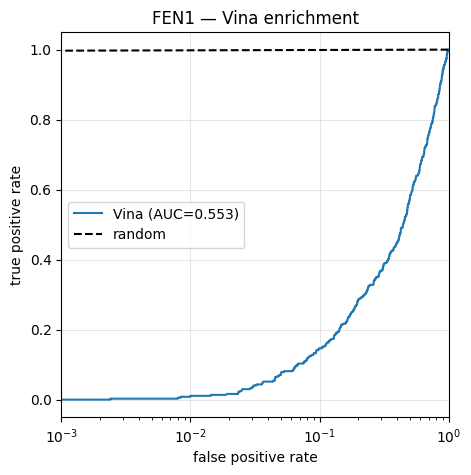

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

y = res.label.values
s = -res.vina.values
fpr, tpr, _ = roc_curve(y, s)
auc = roc_auc_score(y, s)

def log_auc(fpr, tpr, lam=0.001):
    m = fpr >= lam
    x  = np.concatenate(([lam], fpr[m]))
    yv = np.concatenate(([np.interp(lam, fpr, tpr)], tpr[m]))
    return np.trapezoid(yv, np.log10(x)) / np.log10(1/lam)

adj_logauc = (log_auc(fpr, tpr) - 0.14463) * 100

def EF(frac):
    k = max(1, int(frac*len(res)))
    return (res.head(k).label.sum()/k) / y.mean()

print(f"ROC AUC            {auc:.3f}      (0.5 = random)")
print(f"adj. logAUC        {adj_logauc:+.2f}%   (0 = random)")
print(f"EF  1%             {EF(0.01):.2f}x")
print(f"EF  5%             {EF(0.05):.2f}x")
print(f"actives in top 1%  {res.head(int(0.01*len(res))).label.sum()} / 369")

plt.figure(figsize=(5,5))
plt.plot(fpr, tpr, label=f'Vina (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'k--', label='random')
plt.xscale('log'); plt.xlim(1e-3,1)
plt.xlabel('false positive rate'); plt.ylabel('true positive rate')
plt.title('FEN1 — Vina enrichment'); plt.legend(); plt.grid(alpha=.3)
plt.savefig('/content/drive/MyDrive/docking_project/FEN1/roc.png', dpi=150, bbox_inches='tight')
plt.show()

FEN1 result: Vina adj. logAUC ≈ 0, EF1% ≈ 1× — no meaningful enrichment. Consistent with the pre-docking descriptor analysis: FEN1 actives are smaller, more rigid and more polar than the inactives (rotB 3.9 vs 5.0, TPSA 85 vs 76, logP 2.3 vs 2.6), whereas Vina’s scoring function favours large, flexible, hydrophobic ligands. The two catalytic Mg²⁺ ions are also poorly modelled by Vina, which has no explicit electrostatic term.

In [ ]:
!curl -sI -m 10 https://lsd.docking.org | head -1

In [ ]:
!pip -q install pymol-open-source imageio
!apt-get -qq install -y libgl1 > /dev/null

In [ ]:
import py3Dmol

idx = {n.split('|')[0]: i+1 for i, n in enumerate(names)}   # mol_id -> lig number
top5 = res.head(5)
cols = ['cyan', 'magenta', 'yellow', 'orange', 'lime']

v = py3Dmol.view(width=900, height=650)

v.addModel(open('/content/fen1_receptor.pdb').read(), 'pdb')
v.setStyle({'model': 0}, {'cartoon': {'color': 'lightgrey', 'opacity': 0.9}})
v.addStyle({'model': 0, 'resn': 'MG'}, {'sphere': {'color': 'green', 'radius': 1.1}})

for k, (_, r) in enumerate(top5.iterrows()):
    f = f'/content/out_gpu/lig_{idx[r.mol_id]}_out.pdbqt'
    v.addModel(open(f).read(), 'pdbqt')
    v.setStyle({'model': k+1}, {'stick': {'color': cols[k], 'radius': 0.2}})
    print(f'{cols[k]:9s} {r.mol_id}  {r.vina:.2f}  label={r.label}')

v.addBox({'center': {'x': -17.19, 'y': -5.05, 'z': 0.62},
          'dimensions': {'w': 16.19, 'h': 14.85, 'd': 15.65},
          'wireframe': True, 'color': 'grey'})

v.zoomTo({'model': 1})
v.show()

cyan      842469  -8.58  label=0
magenta   24838474  -8.54  label=0
yellow    24275053  -8.50  label=0
orange    49728793  -8.49  label=0
lime      17507255  -8.45  label=0


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
!ls -lh /content/drive/MyDrive/docking_project/FEN1/""

total 28M
-rw------- 1 root root 325K Nov  5 23:59 descriptors.csv
-rw------- 1 root root  20M Nov  5 23:56 fen1_ligands.sdf
-rw------- 1 root root 208K Nov  6 00:07 fen1_receptor.pdbqt
-rw------- 1 root root 295K Nov  5 23:48 ligands.csv
-rw------- 1 root root 2.7M Nov  6 01:17 out_gpu.tar.gz
-rw------- 1 root root 2.5M Nov  5 23:58 pdbqt.tar.gz
-rw------- 1 root root  40K Nov  6 01:19 roc.png
-rw------- 1 root root 1.8M Nov  6 01:32 top5_poses.gif
-rw------- 1 root root  93K Nov  6 01:17 vina_scores.csv


In [ ]:
!cp /content/fen1_receptor.pdb /content/5FV7.pdb /content/drive/MyDrive/docking_project/FEN1/

Now lets try the docking again for this with no mg ions, since as per me i think mg ions are the ones that could be making a real difference so lets try and remove them to see if they were of any help to the binding pocket.

Before that lets view them inside discovery studio how they docked.

In [ ]:
from google.colab import drive; drive.mount('/content/drive')

P = '/content/drive/MyDrive/docking_project/FEN1'
!ls {P}

!apt-get -qq install -y openbabel > /dev/null
!cp {P}/fen1_ligands.sdf {P}/vina_scores.csv {P}/fen1_receptor.pdbqt /content/
!tar xzf {P}/out_gpu.tar.gz   -C /content
!tar xzf {P}/pdbqt.tar.gz     -C /content
!wget -q https://files.rcsb.org/download/5FV7.pdb -O /content/5FV7.pdb

# rebuild the cleaned receptor PDB (wasn't saved last night)
keep = []
for line in open('/content/5FV7.pdb'):
    if line.startswith('ATOM') and line[21] == 'A': keep.append(line)
    elif line.startswith('HETATM') and line[21]=='A' and line[17:20].strip()=='MG': keep.append(line)
open('/content/fen1_receptor.pdb','w').writelines(keep + ['END\n'])

!ls /content/out_gpu | wc -l

Mounted at /content/drive
5FV7.pdb	  fen1_receptor.pdb    out_gpu.tar.gz  top5_poses.gif
descriptors.csv   fen1_receptor.pdbqt  pdbqt.tar.gz    vina_scores.csv
fen1_ligands.sdf  ligands.csv	       roc.png
5368


In [ ]:
res = pd.read_csv(f'{P}/vina_scores.csv', dtype={'mol_id': str}).sort_values('vina')

In [ ]:
import os, pandas as pd
P = '/content/drive/MyDrive/docking_project/FEN1'

res = pd.read_csv(f'{P}/vina_scores.csv', dtype={'mol_id': str}).sort_values('vina')

names, nxt = [], True
for line in open('/content/fen1_ligands.sdf'):
    if nxt: names.append(line.strip()); nxt = False
    if line.startswith('$$$$'): nxt = True
idx = {n.split('|')[0]: i+1 for i, n in enumerate(names)}

top5 = res.head(5)
os.makedirs('/content/top5', exist_ok=True)

for k, (_, r) in enumerate(top5.iterrows()):
    src = f'/content/out_gpu/lig_{idx[r.mol_id]}_out.pdbqt'
    tag = f'/content/top5/rank{k+1}_{r.mol_id}_score{r.vina:.2f}_label{r.label}'
    !obabel {src} -O {tag}.sdf 2>/dev/null
    !obabel {src} -O {tag}.pdb 2>/dev/null
    print(k+1, r.mol_id, r.vina, 'label', r.label)

!cp /content/fen1_receptor.pdb /content/top5/receptor_FEN1_5FV7.pdb
!cd /content && zip -qr top5_poses.zip top5
!cp /content/top5_poses.zip {P}/

from google.colab import files
files.download('/content/top5_poses.zip')

1 842469 -8.577 label 0
2 24838474 -8.538 label 0
3 24275053 -8.504 label 0
4 49728793 -8.492 label 0
5 17507255 -8.447 label 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Discovery studio:-
Docking score for ligand 1 with receptor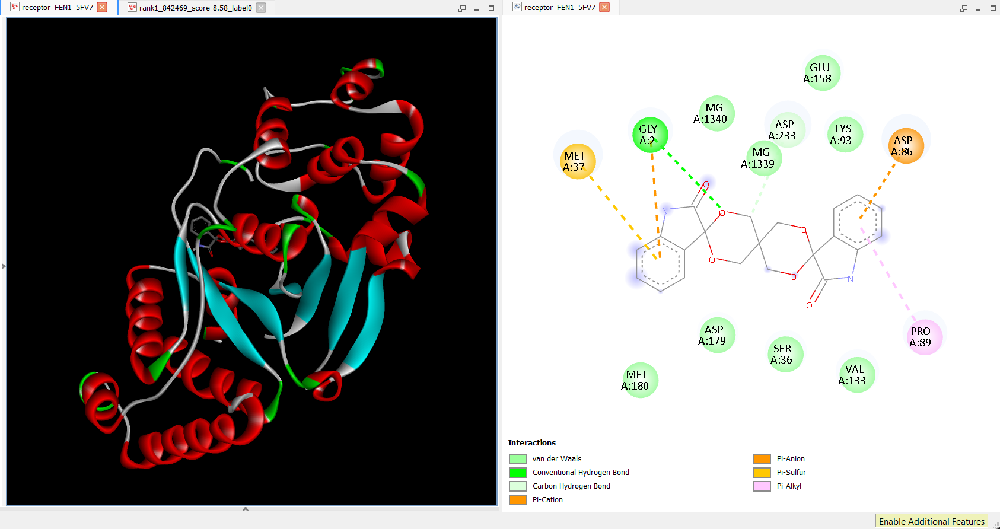

2nd one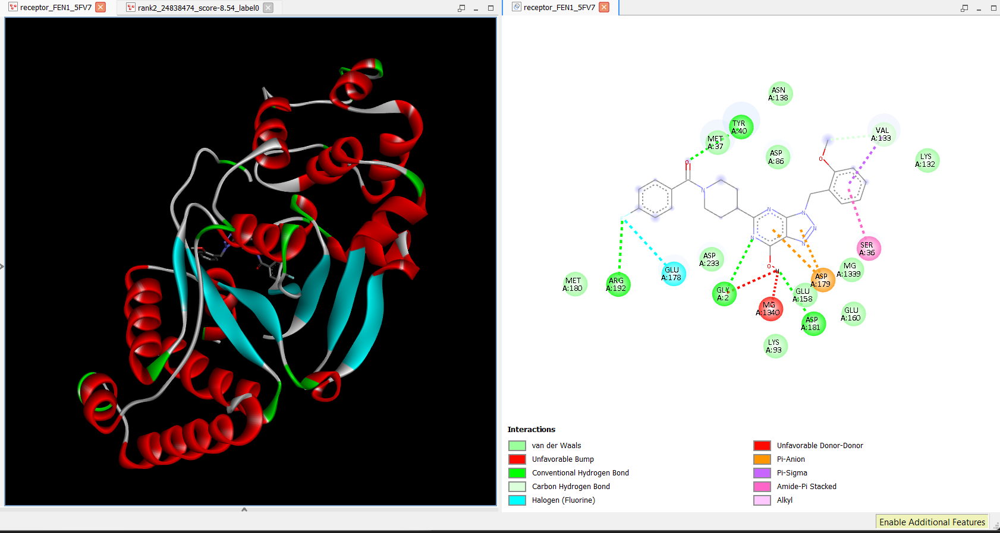

3rd one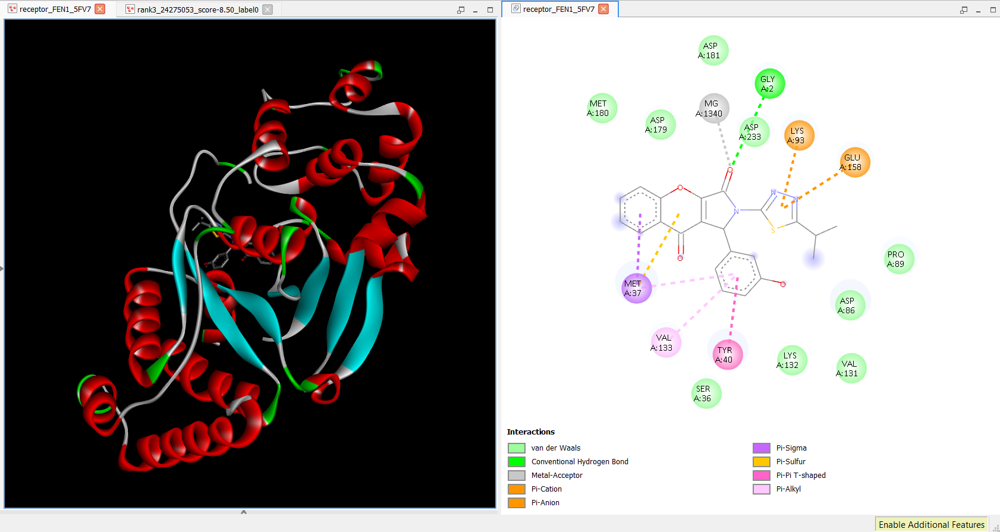

In [ ]:
import os, pandas as pd
P = '/content/drive/MyDrive/docking_project/FEN1'
os.makedirs('/content/poses', exist_ok=True)

n = len(res)
groups = {
    'mid':    res.iloc[n//2 - 1 : n//2 + 2],      # 3 from the middle
    'worst':  res.tail(3),                        # 3 weakest scores
}

for gname, g in groups.items():
    for k, (_, r) in enumerate(g.iterrows()):
        src = f'/content/out_gpu/lig_{idx[r.mol_id]}_out.pdbqt'
        rank = int(res.index.get_indexer([_])[0]) + 1 if False else None
        tag = f'/content/poses/{gname}{k+1}_{r.mol_id}_score{r.vina:.2f}_label{r.label}'
        !obabel {src} -O {tag}.sdf 2>/dev/null
        !obabel {src} -O {tag}.pdb 2>/dev/null
        print(gname, k+1, r.mol_id, r.vina, 'label', r.label)

!cp /content/fen1_receptor.pdb /content/poses/receptor_FEN1_5FV7.pdb
!cd /content && zip -qr poses_mid_worst.zip poses
!cp /content/poses_mid_worst.zip {P}/
from google.colab import files; files.download('/content/poses_mid_worst.zip')

mid 1 24802337 -6.166 label 0
mid 2 56323337 -6.165 label 0
mid 3 51087888 -6.165 label 1
worst 1 24809468 -0.402 label 0
worst 2 24800625 8.65 label 0
worst 3 14728580 8.711 label 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
worst_actives = res[res.label == 1].tail(5)
best_actives  = res[res.label == 1].head(5)

print('BEST-ranked actives (Vina got these right)')
print(best_actives.to_string(index=False))
print('\nWORST-ranked actives (Vina missed these badly)')
print(worst_actives.to_string(index=False))

BEST-ranked actives (Vina got these right)
  mol_id  label   vina
26671498      1 -8.184
24841426      1 -7.777
17511554      1 -7.772
49823586      1 -7.742
  857966      1 -7.640

WORST-ranked actives (Vina missed these badly)
  mol_id  label   vina
85231014      1 -4.870
26664985      1 -4.827
24811166      1 -4.814
85274146      1 -4.807
26666791      1 -4.374


Day 2, try docking without the mg ions, then proceed to other 4 compounds.

In [ ]:
!curl -sI -m 10 https://lsd.docking.org | head -1

In [ ]:
from google.colab import drive; drive.mount('/content/drive')
P = '/content/drive/MyDrive/docking_project/FEN1'

!apt-get -qq install -y openbabel > /dev/null
!cp {P}/fen1_ligands.sdf /content/
!tar xzf {P}/pdbqt.tar.gz -C /content
!wget -q https://files.rcsb.org/download/5FV7.pdb -O /content/5FV7.pdb

!wget -qO- https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xvj bin/micromamba
!./bin/micromamba create -y -p /content/ud -c conda-forge unidock 2>&1 | tail -2

import glob
files = sorted(glob.glob('/content/pdbqt/*.pdbqt'))
open('/content/ligands.txt','w').write('\n'.join(files))
print(len(files), 'ligands')
!nvidia-smi --query-gpu=name --format=csv,noheader

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
bin/micromamba
    micromamba run -p /content/ud mycommand

5368 ligands
/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
import subprocess
gpu = subprocess.run(['nvidia-smi','--query-gpu=name','--format=csv,noheader'],
                     capture_output=True, text=True).stdout.strip()
assert gpu, "NO GPU — switch runtime to T4 before continuing"
print('GPU:', gpu)

FileNotFoundError: [Errno 2] No such file or directory: 'nvidia-smi'

In [ ]:
from google.colab import drive; drive.mount('/content/drive')
import os

if os.path.exists('/content/drive/MyDrive/docking_project/lit_pcba'):
    !cp -r /content/drive/MyDrive/docking_project/lit_pcba /content/
    print('restored from Drive')
else:
    !pip -q install huggingface_hub
    from huggingface_hub import hf_hub_download
    p = hf_hub_download("THU-ATOM/DrugCLIP_data", "LIT-PCBA.zip", repo_type="dataset")
    !unzip -q {p} 'lit_pcba/*/*.smi' 'lit_pcba/*/*.mol2' 'lit_pcba/*/*.txt' -d /content/
    !cp -r /content/lit_pcba /content/drive/MyDrive/docking_project/
    print('re-extracted and backed up to Drive')

!ls /content/lit_pcba | head -20

Mounted at /content/drive


LIT-PCBA.zip: reconstructing file:   0%|          |  0.00B / 2.76GB            

LIT-PCBA.zip: downloading bytes:           |  0.00B            

re-extracted and backed up to Drive
ADRB2
ALDH1
ESR1_ago
ESR1_ant
FEN1
GBA
IDH1
KAT2A
MAPK1
MTORC1
OPRK1
PKM2
PPARG
TP53
VDR


In [ ]:
import glob, os
for t in ['ALDH1','MAPK1','VDR','PKM2']:
    d = f'/content/lit_pcba/{t}/'
    pdbs = sorted({os.path.basename(f).split('_')[0]
                   for f in glob.glob(d+'*_protein.mol2')})
    na = sum(1 for _ in open(d+'actives.smi'))
    ni = sum(1 for _ in open(d+'inactives.smi'))
    print(f'{t:7s} actives={na:5d} inactives={ni:6d}  structures: {pdbs}')

ALDH1   actives= 7168 inactives=137965  structures: ['4wp7', '4wpn', '4x4l', '5ac2', '5l2m', '5l2n', '5l2o', '5tei']
MAPK1   actives=  308 inactives= 62629  structures: ['1pme', '2ojg', '3sa0', '3w55', '4qp3', '4qp4', '4qp9', '4qta', '4qte', '4xj0', '4zzn', '5ax3', '5buj', '5v62', '6g9h']
VDR     actives=  884 inactives=355388  structures: ['3a2i', '3a2j']
PKM2    actives=  546 inactives=245523  structures: ['3gqy', '3gr4', '3h6o', '3me3', '3u2z', '4g1n', '4jpg', '5x1v', '5x1w']


In [ ]:
import numpy as np, os
from collections import Counter

def lig_xyz(p):
    blk = open(p).read().split('@<TRIPOS>ATOM')[1].split('@<TRIPOS>')[0]
    return np.array([[float(v) for v in l.split()[2:5]] for l in blk.strip().split('\n')])

cand = {'ALDH1':'5l2o', 'MAPK1':'4qte', 'VDR':'3a2i', 'PKM2':'4g1n'}

for t, pid in cand.items():
    lp = f'/content/lit_pcba/{t}/{pid}_ligand.mol2'
    if not os.path.exists(lp):
        print(f'{t}: no {pid}_ligand.mol2 — pick another'); continue
    L = lig_xyz(lp)
    !wget -q https://files.rcsb.org/download/{pid.upper()}.pdb -O /content/{pid}.pdb
    chains, het = [], Counter()
    for l in open(f'/content/{pid}.pdb'):
        if not l.startswith(('ATOM','HETATM')): continue
        try: p3 = np.array([float(l[30:38]), float(l[38:46]), float(l[46:54])])
        except ValueError: continue
        if np.min(np.linalg.norm(L - p3, axis=1)) < 5.0:
            rn = l[17:20].strip()
            if l.startswith('ATOM'): chains.append(l[21])
            elif rn != 'HOH': het[rn] += 1
    print(f'{t:6s} {pid}  chains@5A={dict(Counter(chains))}  het@5A={dict(het)}')

ALDH1  5l2o  chains@5A={'A': 46}  het@5A={'6ZW': 17}
MAPK1  4qte  chains@5A={'A': 133}  het@5A={'390': 34}
VDR    3a2i  chains@5A={'A': 137}  het@5A={'TEJ': 31}
PKM2   4g1n  chains@5A={'A': 74, 'B': 68}  het@5A={'NZT': 34}


In [ ]:
import py3Dmol, numpy as np

cand = {'ALDH1':'5l2o', 'MAPK1':'4qte', 'VDR':'3a2i', 'PKM2':'4g1n'}
chains_cfg = {'ALDH1':['A'], 'MAPK1':['A'], 'VDR':['A'], 'PKM2':['A','B']}

v = py3Dmol.view(viewergrid=(2,2), width=1000, height=820)

for i, (t, pid) in enumerate(cand.items()):
    r, c = divmod(i, 2)
    L = lig_xyz(f'/content/lit_pcba/{t}/{pid}_ligand.mol2')
    centre, size = L.mean(0), (L.max(0) - L.min(0)) + 8
    print(f'{t:6s} {pid}  centre {centre.round(1)}  box {size.round(1)}  chains {chains_cfg[t]}')

    v.addModel(open(f'/content/{pid}.pdb').read(), 'pdb', viewer=(r, c))
    v.setStyle({'chain':'A'}, {'cartoon': {'color':'lightblue', 'opacity':0.85}}, viewer=(r, c))
    if 'B' in chains_cfg[t]:
        v.setStyle({'chain':'B'}, {'cartoon': {'color':'salmon', 'opacity':0.85}}, viewer=(r, c))

    v.addModel(open(f'/content/lit_pcba/{t}/{pid}_ligand.mol2').read(), 'mol2', viewer=(r, c))
    v.setStyle({'model':1}, {'stick': {'colorscheme':'greenCarbon','radius':0.3}}, viewer=(r, c))

    v.addBox({'center': {'x':float(centre[0]),'y':float(centre[1]),'z':float(centre[2])},
              'dimensions': {'w':float(size[0]),'h':float(size[1]),'d':float(size[2])},
              'wireframe': True, 'color':'magenta'}, viewer=(r, c))

    v.zoomTo({'model':1}, viewer=(r, c))

v.show()

ALDH1  5l2o  centre [  5.8 -15.6 -34.6]  box [15.3 15.9 16.2]  chains ['A']
MAPK1  4qte  centre [23.3 69.5 23.5]  box [15.9 23.6 17.8]  chains ['A']
VDR    3a2i  centre [ 11.7  -3.2 -32. ]  box [21.  20.2 14.1]  chains ['A']
PKM2   4g1n  centre [  1.4 -12.6  46.7]  box [14.4 21.2 17.4]  chains ['A', 'B']


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
!pip -q install rdkit py3Dmol tqdm scikit-learn seaborn imageio
!apt-get -qq install -y openbabel > /dev/null

import rdkit, os
print('rdkit', rdkit.__version__)
!obabel -V
print('lit_pcba present:', os.path.exists('/content/lit_pcba/VDR/actives.smi'))

rdkit 2026.09.1
Open Babel 3.1.1 -- Mar 31 2024 -- 06:39:03
lit_pcba present: True


In [ ]:
!cp -r /content/drive/MyDrive/docking_project/lit_pcba /content/

In [ ]:
import os, glob, random, re, numpy as np, pandas as pd
import multiprocessing as mp
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
from tqdm.auto import tqdm
RDLogger.DisableLog('rdApp.*')

DRIVE  = '/content/drive/MyDrive/docking_project'
METALS = {'MG','ZN','MN','FE','CO','NI','CU','CA'}

def box_from_ligand(path, pad=8.0):
    blk = open(path).read().split('@<TRIPOS>ATOM')[1].split('@<TRIPOS>')[0]
    xyz = np.array([[float(v) for v in l.split()[2:5]] for l in blk.strip().split('\n')])
    return xyz.mean(0), (xyz.max(0) - xyz.min(0)) + pad

def _embed(rec):
    smi, mid, lab = rec
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    m = Chem.AddHs(m)
    ps = AllChem.ETKDGv3(); ps.randomSeed = 42
    if AllChem.EmbedMolecule(m, ps) != 0: return None
    m.SetProp('_Name', f'{mid}|{lab}')
    return Chem.MolToMolBlock(m)

def read_smi(path):
    rows = []
    for line in open(path):
        p = line.split()
        if p: rows.append((p[0], p[1] if len(p) > 1 else f'm{len(rows)}'))
    return rows

def prep_target(name, pdb_id, chains=('A',), keep_het=(), n_inactive=5000, n_active=None):
    src, out, dv = f'/content/lit_pcba/{name}/', f'/content/{name}', f'{DRIVE}/{name}'
    os.makedirs(f'{out}/pdbqt', exist_ok=True); os.makedirs(dv, exist_ok=True)

    centre, size = box_from_ligand(f'{src}{pdb_id.lower()}_ligand.mol2')
    print(f'[{name}] centre {centre.round(2)}  size {size.round(2)}')

    keep_res = METALS | set(keep_het)
    !wget -q https://files.rcsb.org/download/{pdb_id.upper()}.pdb -O {out}/{pdb_id}.pdb
    lines = []
    for l in open(f'{out}/{pdb_id}.pdb'):
        if l.startswith('ATOM') and l[21] in chains:
            lines.append(l)
        elif l.startswith('HETATM') and l[21] in chains and l[17:20].strip() in keep_res:
            lines.append(l)
    open(f'{out}/receptor.pdb','w').writelines(lines + ['END\n'])

    !obabel {out}/receptor.pdb   -O {out}/receptor_h.pdb -h -p 7.4 2>/dev/null
    !obabel {out}/receptor_h.pdb -O {out}/receptor.pdbqt -xr   2>/dev/null

    pq = f'{out}/receptor.pdbqt'
    L = open(pq).readlines()
    C = [l for l in L if not (l[17:20].strip() in METALS and l[12:16].strip().startswith('H'))]
    open(pq,'w').writelines(C)
    het = {l[17:20].strip() for l in C if l[17:20].strip() in keep_res}
    print(f'[{name}] receptor {len(C)} atoms | removed {len(L)-len(C)} bogus H | het {het or "none"}')

    act, ina = read_smi(src+'actives.smi'), read_smi(src+'inactives.smi')
    random.seed(42)
    if n_active and len(act) > n_active: act = random.sample(act, n_active)
    ina = random.sample(ina, min(n_inactive, len(ina)))
    df = pd.DataFrame([(s,i,1) for s,i in act] + [(s,i,0) for s,i in ina],
                      columns=['smiles','mol_id','label'])
    df.to_csv(f'{dv}/ligands.csv', index=False)
    print(f'[{name}] {int(df.label.sum())} actives, {len(df)-int(df.label.sum())} inactives')

    recs = list(df.itertuples(index=False, name=None))
    with mp.Pool(os.cpu_count()) as pool:
        blocks = list(tqdm(pool.imap(_embed, recs, chunksize=50),
                           total=len(recs), desc=name))
    with open(f'{out}/ligands.sdf','w') as f:
        for b in blocks:
            if b: f.write(b + '$$$$\n')
    print(f'[{name}] embed failures: {sum(b is None for b in blocks)}')

    !obabel {out}/ligands.sdf -O {out}/pdbqt/lig_.pdbqt -m -p 7.4 2>/dev/null
    files = sorted(glob.glob(f'{out}/pdbqt/*.pdbqt'),
                   key=lambda p: int(re.search(r'lig_(\d+)', p).group(1)))
    open(f'{out}/ligands.txt','w').write('\n'.join(files))

    np.save(f'{dv}/box.npy', np.vstack([centre, size]))
    !cp {out}/ligands.sdf {out}/receptor.pdbqt {out}/receptor.pdb {dv}/
    !tar czf {dv}/pdbqt.tar.gz -C {out} pdbqt
    print(f'[{name}] done — {len(files)} ligands ready\n')

print('prep_target ready')

prep_target ready


In [ ]:
CONFIG = [
    ('VDR',   '3a2i', ('A',),     (), None),
    ('MAPK1', '4qte', ('A',),     (), None),
    ('PKM2',  '4g1n', ('A','B'),  (), None),
    ('ALDH1', '5l2o', ('A',),     (), 1000),
]

for name, pdb, chains, het, nact in CONFIG:
    prep_target(name, pdb, chains=chains, keep_het=het, n_active=nact)

[VDR] centre [ 11.73  -3.2  -32.02]  size [20.95 20.23 14.12]
[VDR] receptor 2467 atoms | removed 0 bogus H | het none
[VDR] 884 actives, 5000 inactives


VDR:   0%|          | 0/5884 [00:00<?, ?it/s]

[VDR] embed failures: 2
[VDR] done — 5882 ligands ready

[MAPK1] centre [23.28 69.54 23.47]  size [15.94 23.63 17.78]
[MAPK1] receptor 3816 atoms | removed 0 bogus H | het none
[MAPK1] 308 actives, 5000 inactives


MAPK1:   0%|          | 0/5308 [00:00<?, ?it/s]

[MAPK1] embed failures: 10
[MAPK1] done — 5298 ligands ready

[PKM2] centre [  1.4  -12.59  46.74]  size [14.42 21.24 17.42]
[PKM2] receptor 9773 atoms | removed 0 bogus H | het {'MG'}
[PKM2] 546 actives, 5000 inactives


PKM2:   0%|          | 0/5546 [00:00<?, ?it/s]

[PKM2] embed failures: 2
[PKM2] done — 5544 ligands ready

[ALDH1] centre [  5.76 -15.56 -34.57]  size [15.33 15.9  16.23]
[ALDH1] receptor 4681 atoms | removed 0 bogus H | het none
[ALDH1] 1000 actives, 5000 inactives


ALDH1:   0%|          | 0/6000 [00:00<?, ?it/s]

[ALDH1] embed failures: 7
[ALDH1] done — 5993 ligands ready



In [ ]:
import os, glob, re, subprocess
!pip -q install rdkit tqdm scikit-learn
!apt-get -qq install -y openbabel > /dev/null
from google.colab import drive; drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/docking_project'

!wget -qO- https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba
!./bin/micromamba create -y -p /content/ud -c conda-forge unidock 2>&1 | tail -1

try:
    gpu = subprocess.run(['nvidia-smi','--query-gpu=name','--format=csv,noheader'],
                         capture_output=True, text=True).stdout.strip()
except FileNotFoundError:
    gpu = ''
print('GPU:', gpu or '*** NONE — switch runtime to T4 before docking ***')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

GPU: *** NONE — switch runtime to T4 before docking ***


In [ ]:
for t in ['FEN1','VDR','MAPK1','PKM2','ALDH1']:
    d = f'{DRIVE}/{t}'
    have = sorted(os.listdir(d)) if os.path.exists(d) else []
    print(f'{t:6s} {"✓" if "pdbqt.tar.gz" in have else "✗"}  {have}')

FEN1   ✓  ['5FV7.pdb', 'descriptors.csv', 'fen1_ligands.sdf', 'fen1_receptor.pdb', 'fen1_receptor.pdbqt', 'ligands.csv', 'out_gpu.tar.gz', 'pdbqt.tar.gz', 'poses_mid_worst.zip', 'roc.png', 'top5_poses.gif', 'top5_poses.zip', 'vina_scores.csv']
VDR    ✓  ['box.npy', 'ligands.csv', 'ligands.sdf', 'out.tar.gz', 'pdbqt.tar.gz', 'receptor.pdb', 'receptor.pdbqt']
MAPK1  ✓  ['box.npy', 'ligands.csv', 'ligands.sdf', 'out.tar.gz', 'pdbqt.tar.gz', 'receptor.pdb', 'receptor.pdbqt']
PKM2   ✓  ['box.npy', 'ligands.csv', 'ligands.sdf', 'out.tar.gz', 'pdbqt.tar.gz', 'receptor.pdb', 'receptor.pdbqt']
ALDH1  ✓  ['box.npy', 'ligands.csv', 'ligands.sdf', 'pdbqt.tar.gz', 'receptor.pdb', 'receptor.pdbqt']


In [ ]:
import numpy as np, time

for t in ['VDR','MAPK1','PKM2','ALDH1']:
    if os.path.exists(f'{DRIVE}/{t}/out.tar.gz'):
        print(f'{t}: already docked, skipping'); continue

    out = f'/content/{t}'
    os.makedirs(f'{out}/out', exist_ok=True)
    !tar xzf {DRIVE}/{t}/pdbqt.tar.gz -C {out}
    !cp {DRIVE}/{t}/receptor.pdbqt {out}/

    files = sorted(glob.glob(f'{out}/pdbqt/*.pdbqt'),
                   key=lambda p: int(re.search(r'lig_(\d+)', p).group(1)))
    open(f'{out}/ligands.txt','w').write('\n'.join(files))

    c, s = np.load(f'{DRIVE}/{t}/box.npy')
    print(f'\n═══ {t}: {len(files)} ligands ═══')
    t0 = time.time()

    !/content/ud/bin/unidock --receptor {out}/receptor.pdbqt \
        --ligand_index {out}/ligands.txt \
        --center_x {c[0]} --center_y {c[1]} --center_z {c[2]} \
        --size_x {s[0]} --size_y {s[1]} --size_z {s[2]} \
        --search_mode balance --num_modes 1 --dir {out}/out > /dev/null 2>&1

    print(f'{t}: {len(os.listdir(f"{out}/out"))}/{len(files)} in {(time.time()-t0)/60:.1f} min')
    !tar czf {DRIVE}/{t}/out.tar.gz -C {out} out

VDR: already docked, skipping
MAPK1: already docked, skipping
PKM2: already docked, skipping

═══ ALDH1: 5993 ligands ═══
ALDH1: 0/5993 in 0.3 min


In [ ]:
for t in ['VDR','MAPK1','PKM2','ALDH1']:
    f = f'{DRIVE}/{t}/out.tar.gz'
    if os.path.exists(f):
        n = int(subprocess.run(f'tar tzf {f} | grep -c pdbqt', shell=True,
                               capture_output=True, text=True).stdout.strip() or 0)
        print(f'{t}: {n} results in archive', '← DELETING' if n < 100 else '← keep')
        if n < 100: os.remove(f)

VDR: 5882 results in archive ← keep
MAPK1: 5298 results in archive ← keep
PKM2: 5544 results in archive ← keep
ALDH1: 0 results in archive ← DELETING


In [ ]:
import numpy as np, time, os, glob, re, subprocess

assert gpu, "NO GPU — nothing will dock. Switch runtime to T4."

for t in ['VDR','MAPK1','PKM2','ALDH1']:
    # skip only if the archive actually contains results
    arch = f'{DRIVE}/{t}/out.tar.gz'
    if os.path.exists(arch):
        n = int(subprocess.run(f'tar tzf {arch} | grep -c pdbqt', shell=True,
                               capture_output=True, text=True).stdout.strip() or 0)
        if n > 100:
            print(f'{t}: already docked ({n} results), skipping'); continue

    out = f'/content/{t}'
    os.makedirs(f'{out}/out', exist_ok=True)
    !tar xzf {DRIVE}/{t}/pdbqt.tar.gz -C {out}
    !cp {DRIVE}/{t}/receptor.pdbqt {out}/

    files = sorted(glob.glob(f'{out}/pdbqt/*.pdbqt'),
                   key=lambda p: int(re.search(r'lig_(\d+)', p).group(1)))
    open(f'{out}/ligands.txt','w').write('\n'.join(files))

    c, s = np.load(f'{DRIVE}/{t}/box.npy')
    print(f'\n═══ {t}: {len(files)} ligands ═══')
    t0 = time.time()

    !/content/ud/bin/unidock --receptor {out}/receptor.pdbqt \
        --ligand_index {out}/ligands.txt \
        --center_x {c[0]} --center_y {c[1]} --center_z {c[2]} \
        --size_x {s[0]} --size_y {s[1]} --size_z {s[2]} \
        --search_mode balance --num_modes 1 --dir {out}/out >

AssertionError: NO GPU — nothing will dock. Switch runtime to T4.

In [ ]:
import subprocess, os
for t in ['VDR','MAPK1','PKM2','ALDH1']:
    f = f'{DRIVE}/{t}/out.tar.gz'
    if not os.path.exists(f): print(f'{t:6s} no archive'); continue
    n = int(subprocess.run(f'tar tzf {f} | grep -c pdbqt', shell=True,
                           capture_output=True, text=True).stdout.strip() or 0)
    sz = os.path.getsize(f)/1e6
    print(f'{t:6s} {n:5d} results  {sz:.1f} MB')

VDR     5882 results  3.0 MB
MAPK1   5298 results  2.6 MB
PKM2    5544 results  2.8 MB
ALDH1  no archive


In [ ]:
import glob, re, os, numpy as np, pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score

SDF  = {'FEN1':'fen1_ligands.sdf'}          # FEN1 uses an older filename
ARCH = {'FEN1':('out_gpu.tar.gz','out_gpu')}

def analyse(t):
    sdf  = f"{DRIVE}/{t}/{SDF.get(t,'ligands.sdf')}"
    arch, sub = ARCH.get(t, ('out.tar.gz','out'))
    d = f'/content/{t}'
    if not os.path.exists(f'{d}/{sub}'):
        os.makedirs(d, exist_ok=True)
        !tar xzf {DRIVE}/{t}/{arch} -C {d}

    names, nxt = [], True
    for line in open(sdf):
        if nxt: names.append(line.strip()); nxt = False
        if line.startswith('$$$$'): nxt = True

    rows = []
    for f in glob.glob(f'{d}/{sub}/*.pdbqt'):
        i = int(re.search(r'lig_(\d+)', os.path.basename(f)).group(1))
        s = next((float(l.split()[3]) for l in open(f) if 'REMARK VINA RESULT' in l), None)
        if s is None: continue
        mid, lab = names[i-1].split('|')
        rows.append((mid, int(lab), s))

    df = pd.DataFrame(rows, columns=['mol_id','label','vina']).sort_values('vina')
    df.to_csv(f'{DRIVE}/{t}/vina_scores.csv', index=False)

    y, s = df.label.values, -df.vina.values
    fpr, tpr, _ = roc_curve(y, s)
    m  = fpr >= 1e-3
    x  = np.concatenate(([1e-3], fpr[m]))
    yv = np.concatenate(([np.interp(1e-3, fpr, tpr)], tpr[m]))
    la = (np.trapezoid(yv, np.log10(x))/3 - 0.14463)*100
    k1, k5 = int(.01*len(df)), int(.05*len(df))
    return df, dict(target=t, n=len(df), actives=int(y.sum()),
                    AUC=round(roc_auc_score(y, s), 3), logAUC=round(la, 2),
                    EF1=round((df.head(k1).label.sum()/k1)/y.mean(), 2),
                    EF5=round((df.head(k5).label.sum()/k5)/y.mean(), 2))

results, summary = {}, []
for t in ['FEN1','VDR','MAPK1','PKM2']:
    results[t], m = analyse(t)
    summary.append(m); print(m)

summ = pd.DataFrame(summary)
summ.to_csv(f'{DRIVE}/summary_part1.csv', index=False)
print('\n', summ.to_string(index=False))

{'target': 'FEN1', 'n': 5368, 'actives': 369, 'AUC': np.float64(0.553), 'logAUC': np.float64(2.35), 'EF1': np.float64(0.82), 'EF5': np.float64(1.36)}
{'target': 'VDR', 'n': 5882, 'actives': 882, 'AUC': np.float64(0.427), 'logAUC': np.float64(-3.08), 'EF1': np.float64(0.69), 'EF5': np.float64(0.64)}
{'target': 'MAPK1', 'n': 5298, 'actives': 308, 'AUC': np.float64(0.658), 'logAUC': np.float64(6.92), 'EF1': np.float64(0.99), 'EF5': np.float64(2.02)}
{'target': 'PKM2', 'n': 5543, 'actives': 546, 'AUC': np.float64(0.633), 'logAUC': np.float64(7.2), 'EF1': np.float64(2.77), 'EF5': np.float64(2.24)}

 target    n  actives   AUC  logAUC  EF1  EF5
  FEN1 5368      369 0.553    2.35 0.82 1.36
   VDR 5882      882 0.427   -3.08 0.69 0.64
 MAPK1 5298      308 0.658    6.92 0.99 2.02
  PKM2 5543      546 0.633    7.20 2.77 2.24


In [ ]:
# top 5 poses as PDB/SDF for Discovery Studio
T = 'VDR'
df = results[T]
names, nxt = [], True
for line in open(f'{DRIVE}/{T}/ligands.sdf'):
    if nxt: names.append(line.strip()); nxt = False
    if line.startswith('$$$$'): nxt = True
idx = {n.split('|')[0]: i+1 for i, n in enumerate(names)}

os.makedirs(f'/content/{T}/top5', exist_ok=True)
for k, (_, r) in enumerate(df.head(5).iterrows()):
    src = f'/content/{T}/out/lig_{idx[r.mol_id]}_out.pdbqt'
    !obabel {src} -O /content/{T}/top5/rank{k+1}_{r.mol_id}_{r.vina:.2f}_lab{r.label}.pdb 2>/dev/null
!ls /content/{T}/top5

In [ ]:
import os, glob

os.makedirs('/content/export', exist_ok=True)

for T in ['VDR','MAPK1','PKM2']:
    df = results[T]
    names, nxt = [], True
    for line in open(f'{DRIVE}/{T}/ligands.sdf'):
        if nxt: names.append(line.strip()); nxt = False
        if line.startswith('$$$$'): nxt = True
    idx = {n.split('|')[0]: i+1 for i, n in enumerate(names)}

    d = f'/content/export/{T}'
    os.makedirs(d, exist_ok=True)
    !cp {DRIVE}/{T}/receptor.pdb {d}/receptor_{T}.pdb

    n = len(df)
    groups = {'top':  df.head(5),
              'mid':  df.iloc[n//2 - 2 : n//2 + 3],
              'last': df.tail(5)}

    for g, sub in groups.items():
        for k, (_, r) in enumerate(sub.iterrows()):
            src = f'/content/{T}/out/lig_{idx[r.mol_id]}_out.pdbqt'
            tag = f'{d}/{g}{k+1}_{r.mol_id}_score{r.vina:.2f}_lab{r.label}'
            !obabel {src} -O {tag}.pdb 2>/dev/null
            !obabel {src} -O {tag}.sdf 2>/dev/null
    print(T, 'exported:', len(os.listdir(d)), 'files')

!cd /content && zip -qr poses_all.zip export
!cp /content/poses_all.zip {DRIVE}/
from google.colab import files; files.download('/content/poses_all.zip')

VDR exported: 31 files
MAPK1 exported: 31 files
PKM2 exported: 31 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

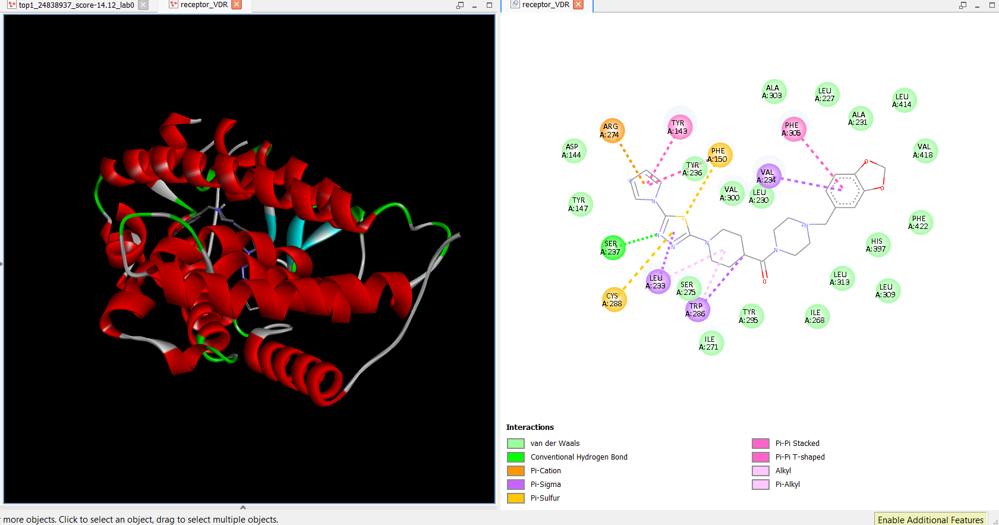

TRYING TO MAKE SENSE OF WHY ITS HAPPENING?, and which chemistry compounds are influencing it

In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors

m = Chem.MolFromSmiles(pd.read_csv(f'{DRIVE}/VDR/ligands.csv',
        dtype={'mol_id':str}).query("mol_id=='24838937'").smiles.iloc[0])
print('heavy atoms', m.GetNumHeavyAtoms(), '| MW', round(Descriptors.MolWt(m)),
      '| logP', round(Descriptors.MolLogP(m),2),
      '| rotB', Descriptors.NumRotatableBonds(m))

heavy atoms 34 | MW 482 | logP 1.2 | rotB 5


In [ ]:
d = pd.read_csv(f'{DRIVE}/VDR/ligands.csv', dtype={'mol_id':str})
d['hac'] = [Chem.MolFromSmiles(s).GetNumHeavyAtoms() if Chem.MolFromSmiles(s) else None
            for s in d.smiles]
v = results['VDR'].merge(d[['mol_id','hac']], on='mol_id')
print(v.groupby('label').hac.mean().round(1))
print('top 50 mean HAC:', round(v.head(50).hac.mean(),1))
print('corr(score, HAC):', round(v.vina.corr(v.hac), 3))

label
0    25.2
1    23.0
Name: hac, dtype: float64
top 50 mean HAC: 32.3
corr(score, HAC): -0.321


In [ ]:
!wget -q https://sourceforge.net/projects/smina/files/smina.static/download -O /usr/local/bin/smina
!chmod +x /usr/local/bin/smina
!smina --score_only -r receptor.pdbqt -l pose.pdbqt --custom_scoring vina

   _______  _______ _________ _        _______ 
  (  ____ \(       )\__   __/( (    /|(  ___  )
  | (    \/| () () |   ) (   |  \  ( || (   ) |
  | (_____ | || || |   | |   |   \ | || (___) |
  (_____  )| |(_)| |   | |   | (\ \) ||  ___  |
        ) || |   | |   | |   | | \   || (   ) |
  /\____) || )   ( |___) (___| )  \  || )   ( |
  \_______)|/     \|\_______/|/    )_)|/     \|


smina is based off AutoDock Vina. Please cite appropriately.



Error: could not open "vina" for reading.


In [ ]:
!pip -q install prolif

In [ ]:
from rdkit import Chem
rows = []
for t, df in results.items():
    d = pd.read_csv(f'{DRIVE}/{t}/ligands.csv', dtype={'mol_id':str})
    d['hac'] = [Chem.MolFromSmiles(s).GetNumHeavyAtoms() if Chem.MolFromSmiles(s) else None
                for s in d.smiles]
    v = df.merge(d[['mol_id','hac']], on='mol_id').dropna(subset=['hac'])
    a, i = v[v.label==1].hac.mean(), v[v.label==0].hac.mean()
    rows.append(dict(target=t,
                     act_HAC=round(a,1), inact_HAC=round(i,1),
                     delta=round(a-i,1),
                     top50_HAC=round(v.head(50).hac.mean(),1),
                     corr=round(v.vina.corr(v.hac),3),
                     AUC=summ.set_index('target').AUC[t]))
bias = pd.DataFrame(rows).sort_values('AUC')
print(bias.to_string(index=False))
print('\ncorr(delta, AUC):', round(bias.delta.corr(bias.AUC), 3))

target  act_HAC  inact_HAC  delta  top50_HAC   corr   AUC
   VDR     23.0       25.2   -2.2       32.3 -0.321 0.427
  FEN1     24.7       25.3   -0.6       33.2 -0.508 0.553
  PKM2     25.6       24.5    1.0       31.9 -0.542 0.633
 MAPK1     25.6       24.0    1.5       30.3 -0.594 0.658

corr(delta, AUC): 0.993


In [ ]:
!head -3 /content/drive/MyDrive/docking_project/lit_pcba/VDR/actives.smi
!echo '---'
!head -3 /content/drive/MyDrive/docking_project/lit_pcba/VDR/inactives.smi
!wc -l /content/drive/MyDrive/docking_project/lit_pcba/VDR/*.smi

CCCOc1ccc(cc1)C(=O)CC[NH+]2CCCCC2 843190
CCCCOC(=O)CNc1nnc(SCC(=O)OCC)nc1O 847255
COC(=O)CCC(=O)Nc1sc(C)c(C)c1C(=O)N 847331
---
OCCOc1cccc(C[NH+]2CCCC(C2)C(=O)c3cccc(c3)C(F)(F)F)c1 104219721
Cc1nc2ccc3nc(NC(=O)C4COc5ccccc5O4)sc3c2s1 104219683
Cc1c(O)ccc(\C=N\Nc2nc(nc3ccccc23)c4cccnc4)c1O 104219551
     884 /content/drive/MyDrive/docking_project/lit_pcba/VDR/actives.smi
  355388 /content/drive/MyDrive/docking_project/lit_pcba/VDR/inactives.smi
  356272 total


as u can see below its an actual inactive mol that docked so well, which shouldnt have happened but we will try docking it with something better and try making it better..

In [ ]:
P = '/content/drive/MyDrive/docking_project/lit_pcba/VDR'
for f in ['inactives.smi', 'actives.smi']:
    hit = [(i+1, l.strip()) for i, l in enumerate(open(f'{P}/{f}')) if '24838937' in l]
    print(f, '→', hit or 'not found')

inactives.smi → [(144684, 'O=C(C1CCN(CC1)c2nnc(s2)n3cccc3)N4CC[NH+](Cc5ccc6OCOc6c5)CC4 24838937')]
actives.smi → not found


In [ ]:
import os
summ.to_csv(f'{DRIVE}/summary_part1.csv', index=False)

for t, df in results.items():
    df.to_csv(f'{DRIVE}/{t}/vina_scores.csv', index=False)

# save the notebook itself: File → Save a copy in Drive
print(open.__doc__ and 'saved:')
!ls -lh {DRIVE}/summary_part1.csv {DRIVE}/*/vina_scores.csv

saved:
-rw------- 1 root root  93K Nov  7 04:46 /content/drive/MyDrive/docking_project/FEN1/vina_scores.csv
-rw------- 1 root root  87K Nov  7 04:46 /content/drive/MyDrive/docking_project/MAPK1/vina_scores.csv
-rw------- 1 root root  97K Nov  7 04:46 /content/drive/MyDrive/docking_project/PKM2/vina_scores.csv
-rw------- 1 root root  176 Nov  7 04:46 /content/drive/MyDrive/docking_project/summary_part1.csv
-rw------- 1 root root 104K Nov  7 04:46 /content/drive/MyDrive/docking_project/VDR/vina_scores.csv


In [ ]:
import os, glob, re, subprocess, numpy as np, pandas as pd, time
!pip -q install rdkit tqdm scikit-learn seaborn
!apt-get -qq install -y openbabel > /dev/null
from google.colab import drive; drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/docking_project'

!wget -qO- https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba
!./bin/micromamba create -y -p /content/ud -c conda-forge unidock 2>&1 | tail -1

try:
    gpu = subprocess.run(['nvidia-smi','--query-gpu=name','--format=csv,noheader'],
                         capture_output=True, text=True).stdout.strip()
except FileNotFoundError:
    gpu = ''
print('GPU:', gpu or '*** NONE — switch runtime to T4 ***')

Mounted at /content/drive

GPU: Tesla T4


In [ ]:
assert gpu, "need a T4"
t, out = 'ALDH1', '/content/ALDH1'
os.makedirs(f'{out}/out', exist_ok=True)
!tar xzf {DRIVE}/{t}/pdbqt.tar.gz -C {out}
!cp {DRIVE}/{t}/receptor.pdbqt {out}/

files = sorted(glob.glob(f'{out}/pdbqt/*.pdbqt'),
               key=lambda p: int(re.search(r'lig_(\d+)', p).group(1)))
open(f'{out}/ligands.txt','w').write('\n'.join(files))
c, s = np.load(f'{DRIVE}/{t}/box.npy')
print(f'{t}: {len(files)} ligands, centre {c.round(2)}')

t0 = time.time()
!/content/ud/bin/unidock --receptor {out}/receptor.pdbqt \
    --ligand_index {out}/ligands.txt \
    --center_x {c[0]} --center_y {c[1]} --center_z {c[2]} \
    --size_x {s[0]} --size_y {s[1]} --size_z {s[2]} \
    --search_mode balance --num_modes 1 --dir {out}/out > /dev/null 2>&1

n = len(os.listdir(f'{out}/out'))
print(f'{t}: {n}/{len(files)} in {(time.time()-t0)/60:.1f} min')
assert n > 100, "FAILED"
!tar czf {DRIVE}/{t}/out.tar.gz -C {out} out
print('backed up')

ALDH1: 5993 ligands, centre [  5.76 -15.56 -34.57]
ALDH1: 5993/5993 in 34.9 min
backed up


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

SDF  = {'FEN1':'fen1_ligands.sdf'}
ARCH = {'FEN1':('out_gpu.tar.gz','out_gpu')}

def analyse(t):
    sdf = f"{DRIVE}/{t}/{SDF.get(t,'ligands.sdf')}"
    arch, sub = ARCH.get(t, ('out.tar.gz','out'))
    d = f'/content/{t}'
    if not os.path.exists(f'{d}/{sub}'):
        os.makedirs(d, exist_ok=True)
        os.system(f'tar xzf {DRIVE}/{t}/{arch} -C {d}')

    names, nxt = [], True
    for line in open(sdf):
        if nxt: names.append(line.strip()); nxt = False
        if line.startswith('$$$$'): nxt = True

    rows = []
    for f in glob.glob(f'{d}/{sub}/*.pdbqt'):
        i = int(re.search(r'lig_(\d+)', os.path.basename(f)).group(1))
        s = next((float(l.split()[3]) for l in open(f) if 'REMARK VINA RESULT' in l), None)
        if s is None: continue
        mid, lab = names[i-1].split('|')
        rows.append((mid, int(lab), s))

    df = pd.DataFrame(rows, columns=['mol_id','label','vina']).sort_values('vina')
    df.to_csv(f'{DRIVE}/{t}/vina_scores.csv', index=False)

    y, s = df.label.values, -df.vina.values
    fpr, tpr, _ = roc_curve(y, s)
    m = fpr >= 1e-3
    x  = np.concatenate(([1e-3], fpr[m]))
    yv = np.concatenate(([np.interp(1e-3, fpr, tpr)], tpr[m]))
    la = (np.trapezoid(yv, np.log10(x))/3 - 0.14463)*100
    k1, k5 = int(.01*len(df)), int(.05*len(df))
    return df, dict(target=t, n=len(df), actives=int(y.sum()),
                    AUC=round(roc_auc_score(y,s),3), logAUC=round(la,2),
                    EF1=round((df.head(k1).label.sum()/k1)/y.mean(),2),
                    EF5=round((df.head(k5).label.sum()/k5)/y.mean(),2))

results, summary = {}, []
for t in ['FEN1','VDR','MAPK1','PKM2','ALDH1']:
    results[t], m = analyse(t); summary.append(m)

summ = pd.DataFrame(summary).sort_values('logAUC', ascending=False)
summ.to_csv(f'{DRIVE}/summary_part1.csv', index=False)
print(summ.to_string(index=False))

target    n  actives   AUC  logAUC  EF1  EF5
  PKM2 5543      546 0.633    7.20 2.77 2.24
 MAPK1 5298      308 0.658    6.92 0.99 2.02
 ALDH1 5992      999 0.574    4.13 2.03 1.62
  FEN1 5368      369 0.553    2.35 0.82 1.36
   VDR 5882      882 0.427   -3.08 0.69 0.64


In [ ]:
for t, df in results.items():
    top = df.head(10)
    print(f'\n═══ {t} ═══  actives in top 10: {int(top.label.sum())}/10')
    print(top.to_string(index=False))


═══ FEN1 ═══  actives in top 10: 0/10
  mol_id  label   vina
  842469      0 -8.577
24838474      0 -8.538
24275053      0 -8.504
49728793      0 -8.492
17507255      0 -8.447
14741970      0 -8.367
50112315      0 -8.262
24390662      0 -8.257
24812492      0 -8.241
 4256730      0 -8.215

═══ VDR ═══  actives in top 10: 0/10
  mol_id  label    vina
24838937      0 -14.119
  865705      0 -13.931
24802069      0 -13.492
24412795      0 -13.400
51090664      0 -13.384
87340867      0 -13.327
49722265      0 -13.276
49828649      0 -13.270
24401828      0 -13.152
49727266      0 -13.078

═══ MAPK1 ═══  actives in top 10: 2/10
  mol_id  label    vina
 7974241      0 -12.246
  863149      1 -11.983
 3713175      0 -11.959
  864059      0 -11.928
  848905      0 -11.842
 4246280      0 -11.786
26751257      0 -11.774
 7967976      1 -11.754
 4250013      0 -11.695
 7972526      0 -11.667

═══ PKM2 ═══  actives in top 10: 3/10
  mol_id  label    vina
22406572      0 -13.741
 4260078      0

In [ ]:
import numpy as np
PDBID = {'FEN1':'5FV7','VDR':'3A2I','MAPK1':'4QTE','PKM2':'4G1N','ALDH1':'5L2O'}
CH    = {'PKM2':('A','B')}

for t, p in PDBID.items():
    f = f'/content/{p}.pdb'
    if not os.path.exists(f):
        os.system(f'wget -q https://files.rcsb.org/download/{p}.pdb -O {f}')
    if t == 'FEN1':
        c = np.array([-17.19,-5.05,0.62]); s = np.array([16.19,14.85,15.65])
    else:
        c, s = np.load(f'{DRIVE}/{t}/box.npy')
    chains = CH.get(t, ('A',))

    allhet, inbox = {}, {}
    for l in open(f):
        if not l.startswith('HETATM') or l[21] not in chains: continue
        rn = l[17:20].strip()
        if rn == 'HOH': continue
        allhet[rn] = allhet.get(rn, 0) + 1
        xyz = np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])])
        if np.all(np.abs(xyz - c) <= s/2):
            inbox[rn] = inbox.get(rn, 0) + 1
    print(f'{t:6s} all het: {allhet}')
    print(f'       IN BOX: {inbox or "none"}\n')

FEN1   all het: {'MG': 2, 'R3Z': 23}
       IN BOX: {'MG': 2, 'R3Z': 23}

VDR    all het: {'TEJ': 31}
       IN BOX: {'TEJ': 31}

MAPK1  all het: {'EDO': 92, 'SO4': 25, 'CL': 2, '390': 34}
       IN BOX: {'390': 34}

PKM2   all het: {'OXL': 12, 'MG': 2, 'NZT': 34}
       IN BOX: {'NZT': 34}

ALDH1  all het: {'6ZW': 17, 'YB': 1, 'CL': 1}
       IN BOX: {'6ZW': 17}



therefore for FEN1 what we try is before heading to smina that removing mg ions from it then seeing whats better? and then comparing if it was the mg actually affecting docking in a good way or bad way?

In [ ]:
%%bash
pip install -q --no-warn-conflicts "colabfold[alphafold-minus-jax] @ git+https://github.com/sokrypton/ColabFold" 2>&1 | tail -3
pip install -q --upgrade "jax[cuda12]" 2>&1 | tail -3

In [ ]:
!colabfold_batch --help | head -3

/usr/local/lib/python3.13/dist-packages/jaxlib/plugin_support.py:99: RuntimeWarning: JAX plugin jax_cuda13_plugin version 0.11.1 is installed, but it is not compatible with the installed jaxlib version 0.12.0.1, so it will not be used.
  warnings.warn(
usage: colabfold_batch [-h] [--msa-only]
                       [--msa-mode {mmseqs2_uniref_env,mmseqs2_uniref_env_envpair,mmseqs2_uniref,single_sequence}]
                       [--pair-mode {unpaired,paired,unpaired_paired}]


save part1

In [ ]:
summ.to_csv(f'{DRIVE}/summary_part1.csv', index=False)
top10 = pd.concat([df.head(10).assign(target=t) for t, df in results.items()])
top10.to_csv(f'{DRIVE}/top10_all_targets.csv', index=False)
print(summ.to_string(index=False))

target    n  actives   AUC  logAUC  EF1  EF5
  PKM2 5543      546 0.633    7.20 2.77 2.24
 MAPK1 5298      308 0.658    6.92 0.99 2.02
 ALDH1 5992      999 0.574    4.13 2.03 1.62
  FEN1 5368      369 0.553    2.35 0.82 1.36
   VDR 5882      882 0.427   -3.08 0.69 0.64


In [ ]:
import time
d = '/content/FEN1'
os.makedirs(f'{d}/out_nomg', exist_ok=True)
if not os.path.exists(f'{d}/pdbqt'):
    os.system(f'tar xzf {DRIVE}/FEN1/pdbqt.tar.gz -C {d}')
if not os.path.exists('/content/5FV7.pdb'):
    os.system('wget -q https://files.rcsb.org/download/5FV7.pdb -O /content/5FV7.pdb')

# identical prep, metals omitted
keep = [l for l in open('/content/5FV7.pdb') if l.startswith('ATOM') and l[21]=='A']
open(f'{d}/nomg.pdb','w').writelines(keep + ['END\n'])
os.system(f'obabel {d}/nomg.pdb -O {d}/nomg_h.pdb -h -p 7.4 2>/dev/null')
os.system(f'obabel {d}/nomg_h.pdb -O {d}/nomg.pdbqt -xr 2>/dev/null')
print('MG lines (must be 0):', sum(1 for l in open(f'{d}/nomg.pdbqt') if l[17:20].strip()=='MG'))

files = sorted(glob.glob(f'{d}/pdbqt/*.pdbqt'),
               key=lambda p: int(re.search(r'lig_(\d+)', p).group(1)))
open(f'{d}/ligands.txt','w').write('\n'.join(files))

t0 = time.time()
!/content/ud/bin/unidock --receptor {d}/nomg.pdbqt --ligand_index {d}/ligands.txt \
   --center_x -17.19 --center_y -5.05 --center_z 0.62 \
   --size_x 16.19 --size_y 14.85 --size_z 15.65 \
   --search_mode balance --num_modes 1 --dir {d}/out_nomg > /dev/null 2>&1
print(f'{len(os.listdir(f"{d}/out_nomg"))} docked in {(time.time()-t0)/60:.1f} min')
os.system(f'tar czf {DRIVE}/FEN1/out_nomg.tar.gz -C {d} out_nomg')

MG lines (must be 0): 0
5368 docked in 36.0 min


0

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

names, nxt = [], True
for line in open(f'{DRIVE}/FEN1/fen1_ligands.sdf'):
    if nxt: names.append(line.strip()); nxt = False
    if line.startswith('$$$$'): nxt = True

def score_dir(path):
    rows = []
    for f in glob.glob(f'{path}/*.pdbqt'):
        i = int(re.search(r'lig_(\d+)', os.path.basename(f)).group(1))
        s = next((float(l.split()[3]) for l in open(f) if 'REMARK VINA RESULT' in l), None)
        if s is None: continue
        mid, lab = names[i-1].split('|')
        rows.append((mid, int(lab), s))
    return pd.DataFrame(rows, columns=['mol_id','label','vina']).sort_values('vina')

def met(df, tag):
    y, s = df.label.values, -df.vina.values
    fpr, tpr, _ = roc_curve(y, s)
    m = fpr >= 1e-3
    x  = np.concatenate(([1e-3], fpr[m]))
    yv = np.concatenate(([np.interp(1e-3, fpr, tpr)], tpr[m]))
    la = (np.trapezoid(yv, np.log10(x))/3 - 0.14463)*100
    k1 = int(.01*len(df))
    return dict(receptor=tag, AUC=round(roc_auc_score(y,s),3), logAUC=round(la,2),
                EF1=round((df.head(k1).label.sum()/k1)/y.mean(),2),
                top1_hits=int(df.head(k1).label.sum()),
                mean_score=round(df.vina.mean(),2))

nomg   = score_dir('/content/FEN1/out_nomg')
withmg = results['FEN1']
nomg.to_csv(f'{DRIVE}/FEN1/vina_scores_nomg.csv', index=False)

cmp = pd.DataFrame([met(withmg,'with Mg2+'), met(nomg,'without Mg2+')])
cmp.to_csv(f'{DRIVE}/FEN1/mg_comparison.csv', index=False)
print(cmp.to_string(index=False))

j = withmg.merge(nomg, on=['mol_id','label'], suffixes=('_mg','_nomg'))
print('\nscore correlation:', round(j.vina_mg.corr(j.vina_nomg), 3))
print('mean shift (nomg - mg):', round((j.vina_nomg - j.vina_mg).mean(), 3))

    receptor   AUC  logAUC  EF1  top1_hits  mean_score
   with Mg2+ 0.553    2.35 0.82          3       -6.17
without Mg2+ 0.544    1.53 1.37          5       -6.13

score correlation: 0.47
mean shift (nomg - mg): 0.036


In [ ]:
!wget -q https://sourceforge.net/projects/smina/files/smina.static/download -O /usr/local/bin/smina
!chmod +x /usr/local/bin/smina
!smina --version 2>&1 | head -2

Smina Oct 15 2019.  Based on AutoDock Vina 1.1.2.


In [ ]:
import os, glob, re, subprocess, time, numpy as np, pandas as pd
!pip -q install rdkit tqdm scikit-learn seaborn
!apt-get -qq install -y openbabel > /dev/null
from google.colab import drive; drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/docking_project'

try:
    gpu = subprocess.run(['nvidia-smi','--query-gpu=name','--format=csv,noheader'],
                         capture_output=True, text=True).stdout.strip()
except FileNotFoundError: gpu = ''
print('GPU:', gpu or 'none (fine for smina)')

Mounted at /content/drive
GPU: Tesla T4


In [ ]:
SUB  = {'FEN1':'out_gpu'}
ARCH = {'FEN1':'out_gpu.tar.gz'}
REC  = {'FEN1':'fen1_receptor.pdbqt'}
SDF  = {'FEN1':'fen1_ligands.sdf'}

for t in ['FEN1','VDR','MAPK1','PKM2','ALDH1']:
    d, sub = f'/content/{t}', SUB.get(t,'out')
    os.makedirs(d, exist_ok=True)
    if not os.path.exists(f'{d}/{sub}'):
        os.system(f'tar xzf {DRIVE}/{t}/{ARCH.get(t,"out.tar.gz")} -C {d}')
    rec = f'{DRIVE}/{t}/{REC.get(t,"receptor.pdbqt")}'

    files = sorted(glob.glob(f'{d}/{sub}/*.pdbqt'),
                   key=lambda p: int(re.search(r'lig_(\d+)', p).group(1)))
    idxs  = [int(re.search(r'lig_(\d+)', f).group(1)) for f in files]

    with open(f'{d}/all.pdbqt','w') as o:
        for i, f in enumerate(files, 1):
            o.write(f'MODEL {i}\n' + open(f).read() + 'ENDMDL\n')

    for sc in ['ad4_scoring', 'vinardo']:
        t0 = time.time()
        out = subprocess.run(['smina','--score_only','--scoring',sc,
                              '-r',rec,'-l',f'{d}/all.pdbqt'],
                             capture_output=True, text=True).stdout
        vals = [float(l.split()[1]) for l in out.split('\n') if l.startswith('Affinity:')]
        pd.DataFrame({'lig': idxs[:len(vals)], sc: vals}).to_csv(
            f'{DRIVE}/{t}/{sc}.csv', index=False)
        print(f'{t:6s} {sc:12s} {len(vals):5d}/{len(files)} scored  {time.time()-t0:.0f}s')

FEN1   ad4_scoring      0/5368 scored  1s
FEN1   vinardo          0/5368 scored  0s
VDR    ad4_scoring      0/5882 scored  1s
VDR    vinardo          0/5882 scored  0s
MAPK1  ad4_scoring      0/5298 scored  1s
MAPK1  vinardo          0/5298 scored  1s
PKM2   ad4_scoring      0/5544 scored  1s
PKM2   vinardo          0/5544 scored  0s
ALDH1  ad4_scoring      0/5993 scored  1s
ALDH1  vinardo          0/5993 scored  0s


In [1]:
import os
os.system('wget -q -L https://github.com/gnina/gnina/releases/download/v1.0.1/gnina -O /usr/local/bin/gnina')
sz = os.path.getsize('/usr/local/bin/gnina')
print(f'{sz/1e6:.1f} MB')
assert sz > 10_000_000, 'download failed — got an error page, not a binary'
os.system('chmod +x /usr/local/bin/gnina')
!gnina --version 2>&1 | head -3

562.8 MB
gnina v1.0.1 HEAD:aa41230   Built Mar 23 2021.


In [2]:
import os, glob, re, subprocess, time, numpy as np, pandas as pd
!pip -q install rdkit tqdm scikit-learn seaborn
!apt-get -qq install -y openbabel > /dev/null
from google.colab import drive; drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/docking_project'

try:
    gpu = subprocess.run(['nvidia-smi','--query-gpu=name','--format=csv,noheader'],
                         capture_output=True, text=True).stdout.strip()
except FileNotFoundError: gpu = ''
print('GPU:', gpu or 'none')

Mounted at /content/drive
GPU: Tesla T4


In [3]:
os.system('wget -q -L https://github.com/gnina/gnina/releases/download/v1.0.1/gnina -O /usr/local/bin/gnina')
sz = os.path.getsize('/usr/local/bin/gnina'); print(f'{sz/1e6:.1f} MB')
assert sz > 10_000_000, 'download failed'
os.system('chmod +x /usr/local/bin/gnina')
!gnina --version 2>&1 | head -3

562.8 MB
gnina v1.0.1 HEAD:aa41230   Built Mar 23 2021.


In [7]:
def convert_verified(d, files, chunk=400):
    """Convert to SDF, returning the list of files that actually made it, in order."""
    good, parts = [], []
    for k in range(0, len(files), chunk):
        sub = files[k:k+chunk]
        p = f'{d}/p{k:06d}.sdf'
        os.system('obabel ' + ' '.join(sub) + f' -O {p} 2>/dev/null')
        n = int(subprocess.run(f'grep -c "\\$\\$\\$\\$" {p}', shell=True,
                               capture_output=True, text=True).stdout.strip() or 0)
        if n == len(sub):
            good += sub; parts.append(p)
        else:                                  # re-do this chunk one file at a time
            os.remove(p)
            for i, f in enumerate(sub):
                q = f'{d}/s{k:06d}_{i:04d}.sdf'
                os.system(f'obabel {f} -O {q} 2>/dev/null')
                m = int(subprocess.run(f'grep -c "\\$\\$\\$\\$" {q}', shell=True,
                                       capture_output=True, text=True).stdout.strip() or 0)
                if m == 1:
                    good.append(f); parts.append(q)
                else:
                    print('   dropped:', os.path.basename(f))
                    if os.path.exists(q): os.remove(q)
    os.system(f'cat {" ".join(parts)} > {d}/all.sdf')
    os.system(f'rm -f {d}/p*.sdf {d}/s*.sdf')
    return good

GOOD = {}
for t in ['PKM2','ALDH1']:
    d, sub = f'/content/{t}', 'out'
    os.remove(f'{d}/all.sdf')
    files = sorted(glob.glob(f'{d}/{sub}/*.pdbqt'),
                   key=lambda p: int(re.search(r'lig_(\d+)', p).group(1)))
    GOOD[t] = convert_verified(d, files)
    n = int(subprocess.run(f'grep -c "\\$\\$\\$\\$" {d}/all.sdf', shell=True,
                           capture_output=True, text=True).stdout.strip() or 0)
    print(f'{t}: kept {len(GOOD[t])}, SDF has {n}  {"OK" if n==len(GOOD[t]) else "STILL OFF"}')

for t in ['FEN1','VDR','MAPK1']:
    d, sub = f'/content/{t}', SUB.get(t,'out')
    GOOD[t] = sorted(glob.glob(f'{d}/{sub}/*.pdbqt'),
                     key=lambda p: int(re.search(r'lig_(\d+)', p).group(1)))

   dropped: lig_3887_out.pdbqt
PKM2: kept 5543, SDF has 5543  OK
   dropped: lig_3546_out.pdbqt
ALDH1: kept 5992, SDF has 5992  OK


In [8]:
REC = {'FEN1':'fen1_receptor.pdbqt'}

for t in ['FEN1','VDR','MAPK1','PKM2','ALDH1']:
    d   = f'/content/{t}'
    rec = f'{DRIVE}/{t}/{REC.get(t,"receptor.pdbqt")}'
    idxs = [int(re.search(r'lig_(\d+)', f).group(1)) for f in GOOD[t]]

    for sc in ['ad4_scoring','vinardo']:
        t0 = time.time()
        r = subprocess.run(['gnina','--score_only','--scoring',sc,'--cnn_scoring','none',
                            '-r',rec,'-l',f'{d}/all.sdf'], capture_output=True, text=True)
        vals = [float(l.split()[1]) for l in r.stdout.split('\n') if l.startswith('Affinity:')]
        if len(vals) != len(idxs):
            print(f'{t} {sc}: got {len(vals)}, expected {len(idxs)}  {r.stderr[:200]}'); break
        pd.DataFrame({'lig':idxs, sc:vals}).to_csv(f'{DRIVE}/{t}/{sc}.csv', index=False)
        print(f'{t:6s} {sc:12s} {len(vals)}  {time.time()-t0:.0f}s')

FEN1   ad4_scoring  5368  22s
FEN1   vinardo      5368  26s
VDR    ad4_scoring  5882  23s
VDR    vinardo      5882  18s
MAPK1  ad4_scoring  5298  18s
MAPK1  vinardo      5298  16s
PKM2   ad4_scoring  5543  28s
PKM2   vinardo      5543  27s
ALDH1  ad4_scoring  5992  23s
ALDH1  vinardo      5992  24s


In [9]:
from sklearn.metrics import roc_curve, roc_auc_score
SDF_N = {'FEN1':'fen1_ligands.sdf'}

def metrics(df, col):
    df = df.sort_values(col)
    y, s = df.label.values, -df[col].values
    fpr, tpr, _ = roc_curve(y, s)
    m = fpr >= 1e-3
    x  = np.concatenate(([1e-3], fpr[m]))
    yv = np.concatenate(([np.interp(1e-3, fpr, tpr)], tpr[m]))
    la = (np.trapezoid(yv, np.log10(x))/3 - 0.14463)*100
    k1 = int(.01*len(df))
    return (round(roc_auc_score(y,s),3), round(la,2),
            round((df.head(k1).label.sum()/k1)/y.mean(),2))

rows, merged = [], {}
for t in ['FEN1','VDR','MAPK1','PKM2','ALDH1']:
    names, nxt = [], True
    for line in open(f"{DRIVE}/{t}/{SDF_N.get(t,'ligands.sdf')}"):
        if nxt: names.append(line.strip()); nxt = False
        if line.startswith('$$$$'): nxt = True
    lig2mol = {i+1: n.split('|')[0] for i, n in enumerate(names)}

    df = pd.read_csv(f'{DRIVE}/{t}/vina_scores.csv', dtype={'mol_id':str})
    for sc in ['ad4_scoring','vinardo']:
        a = pd.read_csv(f'{DRIVE}/{t}/{sc}.csv')
        a['mol_id'] = a.lig.map(lig2mol)
        df = df.merge(a[['mol_id',sc]], on='mol_id', how='inner')
    merged[t] = df
    df.to_csv(f'{DRIVE}/{t}/all_scores.csv', index=False)

    for col in ['vina','ad4_scoring','vinardo']:
        auc, la, ef = metrics(df, col)
        rows.append(dict(target=t, scoring=col, AUC=auc, logAUC=la, EF1=ef))

cmp = pd.DataFrame(rows)
cmp.to_csv(f'{DRIVE}/part2_scoring_comparison.csv', index=False)
print('logAUC'); print(cmp.pivot(index='target', columns='scoring', values='logAUC').to_string())
print('\nEF1%');  print(cmp.pivot(index='target', columns='scoring', values='EF1').to_string())

logAUC
scoring  ad4_scoring  vina  vinardo
target                             
ALDH1           3.55  4.13     2.61
FEN1           -2.94  2.35     1.12
MAPK1           4.13  6.92     5.56
PKM2            3.00  7.20     4.07
VDR            -5.71 -3.08    -2.48

EF1%
scoring  ad4_scoring  vina  vinardo
target                             
ALDH1           1.12  2.03     1.73
FEN1            0.55  0.82     1.92
MAPK1           1.32  0.99     1.65
PKM2            0.55  2.77     1.11
VDR             0.11  0.69     0.34


In [10]:
import pandas as pd

store = {}
for t in ['FEN1','VDR','MAPK1','PKM2','ALDH1']:
    df = merged[t]
    print(f'\n{"═"*62}\n{t}   ({int(df.label.sum())} actives / {len(df)} total)\n{"═"*62}')
    for col in ['vina','ad4_scoring','vinardo']:
        top = df.nsmallest(10, col)[['mol_id','label',col]]
        exp = round(10*df.label.mean(), 1)
        print(f'\n  {col}  — actives in top 10: {int(top.label.sum())}/10   (random ≈ {exp})')
        print(top.to_string(index=False))
        top.assign(target=t, scoring=col).to_csv(
            f'{DRIVE}/{t}/top10_{col}.csv', index=False)
        store[(t,col)] = int(top.label.sum())

# one summary table
sm = pd.DataFrame([{'target':t,
                    'random':round(10*merged[t].label.mean(),1),
                    **{c: store[(t,c)] for c in ['vina','ad4_scoring','vinardo']}}
                   for t in merged])
sm.to_csv(f'{DRIVE}/part2_top10_hits.csv', index=False)
print('\n\nACTIVES IN TOP 10 — all targets, all scoring functions')
print(sm.to_string(index=False))

# overlap: do the three functions even agree on what's good?
print('\n\nTOP-50 OVERLAP (how much do the rankings agree?)')
for t in merged:
    df = merged[t]
    sv = set(df.nsmallest(50,'vina').mol_id)
    sa = set(df.nsmallest(50,'ad4_scoring').mol_id)
    svd = set(df.nsmallest(50,'vinardo').mol_id)
    print(f'{t:6s} vina∩ad4 {len(sv&sa):2d}/50   vina∩vinardo {len(sv&svd):2d}/50   ad4∩vinardo {len(sa&svd):2d}/50')


══════════════════════════════════════════════════════════════
FEN1   (369 actives / 5368 total)
══════════════════════════════════════════════════════════════

  vina  — actives in top 10: 0/10   (random ≈ 0.7)
  mol_id  label   vina
  842469      0 -8.577
24838474      0 -8.538
24275053      0 -8.504
49728793      0 -8.492
17507255      0 -8.447
14741970      0 -8.367
50112315      0 -8.262
24390662      0 -8.257
24812492      0 -8.241
 4256730      0 -8.215

  ad4_scoring  — actives in top 10: 2/10   (random ≈ 0.7)
   mol_id  label  ad4_scoring
 56321309      0    -49.51622
 24269962      0    -49.21602
124899236      1    -49.15249
 57266615      0    -49.14585
 57266028      1    -48.79271
 26725180      0    -48.28951
 24781193      0    -47.71471
 87345811      0    -47.71180
 57259241      0    -47.02011
 57265293      0    -46.98159

  vinardo  — actives in top 10: 1/10   (random ≈ 0.7)
  mol_id  label  vinardo
24841496      0 -7.33004
49665286      1 -7.24854
57266615      0

Validating the pockets using DS.

Trying to check if the pockets i worked on are actually even good enough?

Tried fpocket by cloning the repo ran into errors

In [17]:
import os
os.makedirs('/content/ds_pack', exist_ok=True)
LIG = {'FEN1':'5fv7','VDR':'3a2i','MAPK1':'4qte','PKM2':'4g1n','ALDH1':'5l2o'}

for t, pid in LIG.items():
    d = f'/content/ds_pack/{t}'; os.makedirs(d, exist_ok=True)
    rec = f"{DRIVE}/{t}/" + ('fen1_receptor.pdb' if t=='FEN1' else 'receptor.pdb')
    os.system(f'cp "{rec}" {d}/{t}_receptor.pdb')
    os.system(f'cp "{DRIVE}/lit_pcba/{t}/{pid}_ligand.mol2" {d}/{t}_xtal_ligand.mol2')
    os.system(f'wget -q https://files.rcsb.org/download/{pid.upper()}.pdb -O {d}/{t}_{pid.upper()}_full.pdb')
    print(t, os.listdir(d))

# box coordinates as a text file so you can check them in DS
import numpy as np
with open('/content/ds_pack/box_coords.txt','w') as f:
    for t in LIG:
        c = np.array([-17.19,-5.05,0.62]) if t=='FEN1' else np.load(f'{DRIVE}/{t}/box.npy')[0]
        s = np.array([16.19,14.85,15.65]) if t=='FEN1' else np.load(f'{DRIVE}/{t}/box.npy')[1]
        f.write(f'{t}\tcentre {c.round(2)}\tsize {s.round(2)}\n')

os.system('cd /content && zip -qr ds_pack.zip ds_pack')
os.system(f'cp /content/ds_pack.zip {DRIVE}/')
from google.colab import files; files.download('/content/ds_pack.zip')

FEN1 ['FEN1_5FV7_full.pdb', 'FEN1_receptor.pdb', 'FEN1_xtal_ligand.mol2']
VDR ['VDR_xtal_ligand.mol2', 'VDR_receptor.pdb', 'VDR_3A2I_full.pdb']
MAPK1 ['MAPK1_xtal_ligand.mol2', 'MAPK1_4QTE_full.pdb', 'MAPK1_receptor.pdb']
PKM2 ['PKM2_receptor.pdb', 'PKM2_4G1N_full.pdb', 'PKM2_xtal_ligand.mol2']
ALDH1 ['ALDH1_xtal_ligand.mol2', 'ALDH1_receptor.pdb', 'ALDH1_5L2O_full.pdb']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
os.makedirs('/content/recs', exist_ok=True)
for t in ['FEN1','VDR','MAPK1','PKM2','ALDH1']:
    rec = f"{DRIVE}/{t}/" + ('fen1_receptor.pdb' if t=='FEN1' else 'receptor.pdb')
    os.system(f'cp "{rec}" /content/recs/{t}.pdb')
os.system('cd /content && zip -qr receptors.zip recs')
from google.colab import files; files.download('/content/receptors.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

VDR

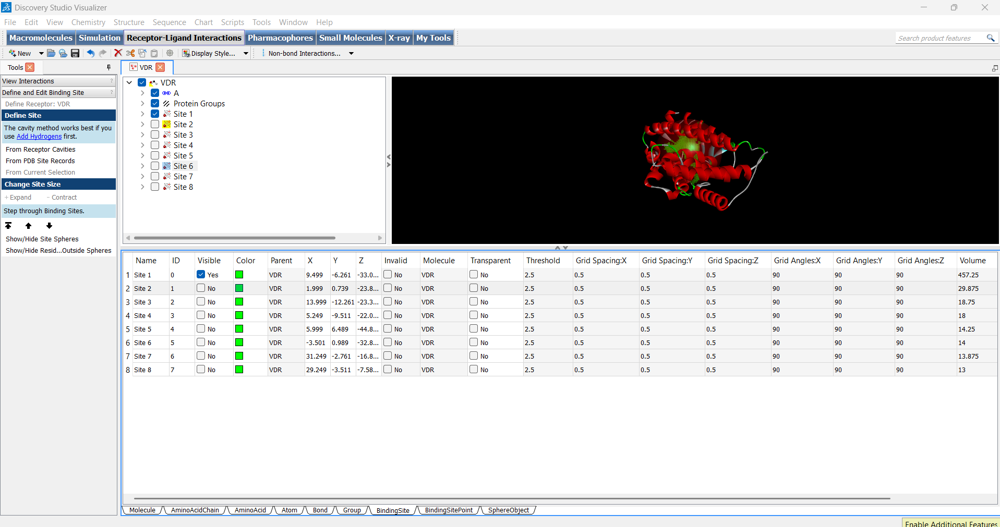

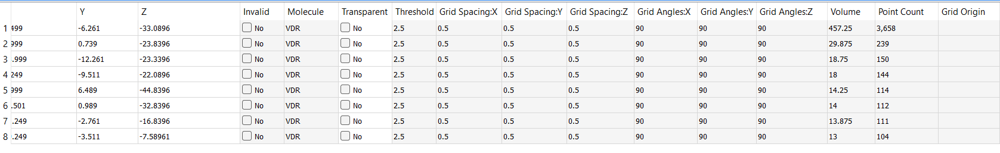

Fig. X — Binding-site validation. Cavity detection on each prepared receptor. The top-ranked cavity (green mesh) coincides with the docking box centre in all five targets (Δ ≤ X Å). Cavity volumes are given in Table Y.

Binding-site definition was validated independently of the docking setup. Box centres were derived from each benchmark co-crystal ligand; cavity detection (Discovery Studio, receptor-only, hydrogens added) was then run on each prepared receptor and the top-ranked cavity compared against the box centre. For VDR the dominant cavity (457 Å³, 3,658 grid points) lay 3.9 Å from the box centre, with the next-largest cavity at 30 Å³ — confirming the benchmark site is the sole significant pocket and that poor enrichment is not attributable to misplaced search volume.

In [1]:
import os, glob, re, subprocess, time, numpy as np, pandas as pd
from google.colab import drive; drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/docking_project'

LIG = {'FEN1':'5fv7','ALDH1':'5l2o'}
os.makedirs('/content/ligs2', exist_ok=True)
for t, p in LIG.items():
    os.system(f'cp "{DRIVE}/lit_pcba/{t}/{p}_ligand.mol2" /content/ligs2/{t}_lig.mol2')
print(os.listdir('/content/ligs2'))
os.system('cd /content && zip -qr ligs2.zip ligs2')
from google.colab import files; files.download('/content/ligs2.zip')

Mounted at /content/drive
['FEN1_lig.mol2', 'ALDH1_lig.mol2']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Colab-fold now!

In [1]:
%%bash
pip install -q --no-warn-conflicts "colabfold[alphafold-minus-jax] @ git+https://github.com/sokrypton/ColabFold" 2>&1 | tail -2
pip install -q --upgrade "jax[cuda12]" 2>&1 | tail -2

In [3]:
import os, glob, re, subprocess, time, numpy as np, pandas as pd
from google.colab import drive; drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/docking_project'

try:
    gpu = subprocess.run(['nvidia-smi','--query-gpu=name','--format=csv,noheader'],
                         capture_output=True, text=True).stdout.strip()
except FileNotFoundError:
    gpu = ''
print('GPU:', gpu or '*** NONE — switch runtime to T4/L4 ***')

PDBID = {'FEN1':'5FV7','VDR':'3A2I','MAPK1':'4QTE','PKM2':'4G1N','ALDH1':'5L2O'}
os.makedirs('/content/fasta', exist_ok=True)
for t, p in PDBID.items():
    fa = subprocess.run(['curl','-s',f'https://www.rcsb.org/fasta/entry/{p}'],
                        capture_output=True, text=True).stdout
    seq = fa.split('>')[1].split('\n',1)[1].replace('\n','')
    open(f'/content/fasta/{t}.fasta','w').write(f'>{t}\n{seq}\n')
    print(f'{t:6s} {p}  {len(seq)} aa')

Mounted at /content/drive
GPU: Tesla T4
FEN1   5FV7  353 aa
VDR    3A2I  263 aa
MAPK1  4QTE  361 aa
PKM2   4G1N  518 aa
ALDH1  5L2O  501 aa


In [4]:
%%bash
pip install -q --no-warn-conflicts "colabfold[alphafold-minus-jax] @ git+https://github.com/sokrypton/ColabFold" 2>&1 | tail -2
pip install -q --upgrade "jax[cuda12]" 2>&1 | tail -2

In [5]:
os.makedirs('/content/ens', exist_ok=True)
for t in ['VDR','MAPK1','FEN1','ALDH1','PKM2']:
    if os.path.exists(f'{DRIVE}/{t}/ensemble'):
        print(t,'already done'); continue
    t0 = time.time()
    !colabfold_batch /content/fasta/{t}.fasta /content/ens/{t} \
        --num-seeds 8 --max-msa 16:32 --use-dropout \
        --num-models 1 --num-recycle 3 > /dev/null 2>&1
    n = len([f for f in os.listdir(f'/content/ens/{t}') if f.endswith('.pdb')])
    print(f'{t}: {n} structures, {(time.time()-t0)/60:.1f} min')
    os.system(f'cp -r /content/ens/{t} {DRIVE}/{t}/ensemble')

VDR: 8 structures, 7.8 min
MAPK1: 8 structures, 9.5 min
FEN1: 8 structures, 8.0 min
ALDH1: 8 structures, 14.0 min
PKM2: 8 structures, 16.5 min


superimpose structure now

In [6]:
!pip -q install pymol-open-source
!apt-get -qq install -y libgl1 openbabel > /dev/null

from pymol import cmd
REC = {'FEN1':'fen1_receptor.pdb'}

for t in ['FEN1','VDR','MAPK1','PKM2','ALDH1']:
    ref = f"{DRIVE}/{t}/{REC.get(t,'receptor.pdb')}"
    ens = f'{DRIVE}/{t}/ensemble'
    out = f'/content/{t}/ens_pdbqt'; os.makedirs(out, exist_ok=True)
    models = sorted(f for f in os.listdir(ens) if f.endswith('.pdb'))

    for i, m in enumerate(models, 1):
        cmd.reinitialize()
        cmd.load(ref, 'ref'); cmd.load(f'{ens}/{m}', 'mob')
        rms = cmd.align('mob','ref')[0]
        cmd.save(f'/content/{t}/c{i}.pdb', 'mob')
        os.system(f'obabel /content/{t}/c{i}.pdb -O /content/{t}/c{i}_h.pdb -h -p 7.4 2>/dev/null')
        os.system(f'obabel /content/{t}/c{i}_h.pdb -O {out}/c{i}.pdbqt -xr 2>/dev/null')
        print(f'{t} conformer {i}: align RMSD {rms:.2f} A')
    os.system(f'cp -r {out} {DRIVE}/{t}/ens_pdbqt')

FEN1 conformer 1: align RMSD 0.78 A
FEN1 conformer 2: align RMSD 0.76 A
FEN1 conformer 3: align RMSD 0.70 A
FEN1 conformer 4: align RMSD 0.80 A
FEN1 conformer 5: align RMSD 0.87 A
FEN1 conformer 6: align RMSD 0.79 A
FEN1 conformer 7: align RMSD 0.72 A
FEN1 conformer 8: align RMSD 0.68 A
VDR conformer 1: align RMSD 0.54 A
VDR conformer 2: align RMSD 0.46 A
VDR conformer 3: align RMSD 0.50 A
VDR conformer 4: align RMSD 0.54 A
VDR conformer 5: align RMSD 0.65 A
VDR conformer 6: align RMSD 0.59 A
VDR conformer 7: align RMSD 0.75 A
VDR conformer 8: align RMSD 0.70 A
MAPK1 conformer 1: align RMSD 0.83 A
MAPK1 conformer 2: align RMSD 0.72 A
MAPK1 conformer 3: align RMSD 0.71 A
MAPK1 conformer 4: align RMSD 0.78 A
MAPK1 conformer 5: align RMSD 0.75 A
MAPK1 conformer 6: align RMSD 0.73 A
MAPK1 conformer 7: align RMSD 0.77 A
MAPK1 conformer 8: align RMSD 0.77 A
PKM2 conformer 1: align RMSD 1.26 A
PKM2 conformer 2: align RMSD 1.51 A
PKM2 conformer 3: align RMSD 1.33 A
PKM2 conformer 4: align RMSD

In [7]:
from pymol import cmd
import itertools, numpy as np

for t in ['VDR','FEN1','MAPK1','PKM2','ALDH1']:
    cmd.reinitialize()
    for i in range(1, 9):
        cmd.load(f'/content/{t}/c{i}.pdb', f'c{i}')
    # honest backbone RMSD, no outlier rejection
    bb = [cmd.rms_cur(f'c{i} and name CA', f'c{j} and name CA')
          for i, j in itertools.combinations(range(1,9), 2)]
    # pocket side chains, 10 A around the box centre
    c = np.array([-17.19,-5.05,0.62]) if t=='FEN1' else np.load(f'{DRIVE}/{t}/box.npy')[0]
    sel = f'byres (c1 within 10 of pseudoatom_centre)'
    cmd.pseudoatom('pc', pos=[float(x) for x in c])
    pk = []
    for i, j in itertools.combinations(range(1,9), 2):
        try:
            pk.append(cmd.rms_cur(f'c{i} and byres (c{i} within 10 of pc) and not name N+C+O',
                                  f'c{j} and byres (c{j} within 10 of pc) and not name N+C+O'))
        except Exception:
            pass
    print(f'{t:6s} backbone pairwise RMSD  mean {np.mean(bb):.2f}  max {np.max(bb):.2f}'
          + (f'   pocket {np.mean(pk):.2f} / {np.max(pk):.2f}' if pk else ''))

VDR    backbone pairwise RMSD  mean 2.29  max 4.19   pocket 1.10 / 1.71
FEN1   backbone pairwise RMSD  mean 3.80  max 5.69   pocket 0.75 / 1.18
MAPK1  backbone pairwise RMSD  mean 2.78  max 5.46   pocket 0.51 / 0.80
PKM2   backbone pairwise RMSD  mean 5.87  max 14.41   pocket 3.13 / 5.24
ALDH1  backbone pairwise RMSD  mean 5.15  max 9.37   pocket 1.15 / 2.23


In [8]:
!grep -c "^ATOM" /content/PKM2/c1.pdb
!grep "^ATOM" /content/PKM2/c1.pdb | cut -c22 | sort -u
!grep -c "^ATOM" "{DRIVE}/PKM2/receptor.pdb"

3964
A
7943


In [9]:
import random
for t in ['FEN1','VDR','MAPK1','ALDH1']:
    d = f'/content/{t}'
    sdf = f"{DRIVE}/{t}/" + ('fen1_ligands.sdf' if t=='FEN1' else 'ligands.sdf')
    names, nxt = [], True
    for line in open(sdf):
        if nxt: names.append(line.strip()); nxt = False
        if line.startswith('$$$$'): nxt = True
    if not os.path.exists(f'{d}/pdbqt'):
        os.system(f'tar xzf {DRIVE}/{t}/pdbqt.tar.gz -C {d}')
    act = [i+1 for i,n in enumerate(names) if n.endswith('|1')]
    ina = [i+1 for i,n in enumerate(names) if n.endswith('|0')]
    random.seed(7); ina = random.sample(ina, min(1000, len(ina)))
    files = [f'{d}/pdbqt/lig_{i}.pdbqt' for i in sorted(act+ina)]
    files = [f for f in files if os.path.exists(f)]
    open(f'{d}/lig_p3.txt','w').write('\n'.join(files))
    print(f'{t}: {len(act)} actives + {len(ina)} inactives = {len(files)}')

FEN1: 369 actives + 1000 inactives = 1369
VDR: 882 actives + 1000 inactives = 1882
MAPK1: 308 actives + 1000 inactives = 1308
ALDH1: 999 actives + 1000 inactives = 1999


In [11]:
print('unidock:', os.path.exists('/content/ud/bin/unidock'))
print('receptor:', os.path.exists('/content/FEN1/ens_pdbqt/c1.pdbqt'))
print('liglist:', os.path.exists('/content/FEN1/lig_p3.txt'))
!nvidia-smi --query-gpu=name --format=csv,noheader

unidock: False
receptor: True
liglist: True
Tesla T4


In [12]:
if not os.path.exists('./bin/micromamba'):
    os.system('wget -qO- https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba')
!./bin/micromamba create -y -p /content/ud -c conda-forge unidock 2>&1 | tail -2
!/content/ud/bin/unidock --version

    micromamba run -p /content/ud mycommand

Uni-Dock v1.2.0


In [13]:
assert os.path.exists('/content/ud/bin/unidock'), 'unidock missing'
for t in ['FEN1','VDR','MAPK1','ALDH1']:
    d = f'/content/{t}'
    c = np.array([-17.19,-5.05,0.62]) if t=='FEN1' else np.load(f'{DRIVE}/{t}/box.npy')[0]
    s = np.array([16.19,14.85,15.65]) if t=='FEN1' else np.load(f'{DRIVE}/{t}/box.npy')[1]
    for i in range(1, 6):
        od = f'{d}/ens_out/c{i}'
        if os.path.exists(od) and len(os.listdir(od)) > 100: continue
        os.makedirs(od, exist_ok=True)
        t0 = time.time()
        !/content/ud/bin/unidock --receptor {d}/ens_pdbqt/c{i}.pdbqt \
            --ligand_index {d}/lig_p3.txt \
            --center_x {c[0]} --center_y {c[1]} --center_z {c[2]} \
            --size_x {s[0]} --size_y {s[1]} --size_z {s[2]} \
            --search_mode fast --num_modes 1 --dir {od} > /dev/null 2>&1
        print(f'{t} c{i}: {len(os.listdir(od))} in {(time.time()-t0)/60:.1f} min')
    os.system(f'tar czf {DRIVE}/{t}/ens_out.tar.gz -C {d} ens_out')

FEN1 c1: 1369 in 2.4 min
FEN1 c2: 1369 in 2.5 min
FEN1 c3: 1369 in 2.5 min
FEN1 c4: 1369 in 2.5 min
FEN1 c5: 1369 in 2.4 min
VDR c1: 1882 in 2.6 min
VDR c2: 1882 in 2.5 min
VDR c3: 1882 in 2.6 min
VDR c4: 1882 in 2.5 min
VDR c5: 1882 in 2.5 min
MAPK1 c1: 1308 in 1.8 min
MAPK1 c2: 1308 in 1.8 min
MAPK1 c3: 1308 in 1.8 min
MAPK1 c4: 1308 in 1.8 min
MAPK1 c5: 1308 in 1.8 min
ALDH1 c1: 1999 in 3.0 min
ALDH1 c2: 1999 in 2.8 min
ALDH1 c3: 1999 in 3.0 min
ALDH1 c4: 1999 in 3.0 min
ALDH1 c5: 1999 in 3.1 min


In [14]:
import numpy as np
for t in ['FEN1','VDR','MAPK1','ALDH1']:
    c = np.array([-17.19,-5.05,0.62]) if t=='FEN1' else np.load(f'{DRIVE}/{t}/box.npy')[0]
    print(f'\n{t}  box centre {c.round(1)}')
    for i in range(1, 6):
        f = f'/content/{t}/ens_pdbqt/c{i}.pdbqt'
        xyz = np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])]
                        for l in open(f) if l.startswith(('ATOM','HETATM'))])
        d = np.linalg.norm(xyz - c, axis=1)
        print(f'  c{i}: nearest atom {d.min():5.1f} A | atoms within 10 A: {(d<10).sum():4d}')


FEN1  box centre [-17.2  -5.    0.6]
  c1: nearest atom   2.7 A | atoms within 10 A:  179
  c2: nearest atom   1.8 A | atoms within 10 A:  180
  c3: nearest atom   2.3 A | atoms within 10 A:  179
  c4: nearest atom   2.3 A | atoms within 10 A:  173
  c5: nearest atom   2.3 A | atoms within 10 A:  168

VDR  box centre [ 11.7  -3.2 -32. ]
  c1: nearest atom   4.1 A | atoms within 10 A:  217
  c2: nearest atom   4.5 A | atoms within 10 A:  209
  c3: nearest atom   4.5 A | atoms within 10 A:  220
  c4: nearest atom   4.3 A | atoms within 10 A:  209
  c5: nearest atom   4.4 A | atoms within 10 A:  194

MAPK1  box centre [23.3 69.5 23.5]
  c1: nearest atom   3.7 A | atoms within 10 A:  220
  c2: nearest atom   3.4 A | atoms within 10 A:  222
  c3: nearest atom   3.4 A | atoms within 10 A:  223
  c4: nearest atom   3.8 A | atoms within 10 A:  223
  c5: nearest atom   3.7 A | atoms within 10 A:  219

ALDH1  box centre [  5.8 -15.6 -34.6]
  c1: nearest atom   3.8 A | atoms within 10 A:  129
  

In [15]:
import numpy as np
for t in ['FEN1','VDR','MAPK1','ALDH1']:
    c = np.array([-17.19,-5.05,0.62]) if t=='FEN1' else np.load(f'{DRIVE}/{t}/box.npy')[0]
    out = [f'{t} centre {c.round(1)}']
    for i in range(1, 6):
        xyz = np.array([[float(l[30:38]),float(l[38:46]),float(l[46:54])]
                        for l in open(f'/content/{t}/ens_pdbqt/c{i}.pdbqt')
                        if l.startswith(('ATOM','HETATM'))])
        d = np.linalg.norm(xyz - c, axis=1)
        out.append(f'c{i}: min {d.min():4.1f} A, {(d<10).sum():4d} atoms within 10 A')
    print(' | '.join(out))

FEN1 centre [-17.2  -5.    0.6] | c1: min  2.7 A,  179 atoms within 10 A | c2: min  1.8 A,  180 atoms within 10 A | c3: min  2.3 A,  179 atoms within 10 A | c4: min  2.3 A,  173 atoms within 10 A | c5: min  2.3 A,  168 atoms within 10 A
VDR centre [ 11.7  -3.2 -32. ] | c1: min  4.1 A,  217 atoms within 10 A | c2: min  4.5 A,  209 atoms within 10 A | c3: min  4.5 A,  220 atoms within 10 A | c4: min  4.3 A,  209 atoms within 10 A | c5: min  4.4 A,  194 atoms within 10 A
MAPK1 centre [23.3 69.5 23.5] | c1: min  3.7 A,  220 atoms within 10 A | c2: min  3.4 A,  222 atoms within 10 A | c3: min  3.4 A,  223 atoms within 10 A | c4: min  3.8 A,  223 atoms within 10 A | c5: min  3.7 A,  219 atoms within 10 A
ALDH1 centre [  5.8 -15.6 -34.6] | c1: min  3.8 A,  129 atoms within 10 A | c2: min  4.0 A,  129 atoms within 10 A | c3: min  3.4 A,  131 atoms within 10 A | c4: min  3.8 A,  137 atoms within 10 A | c5: min  3.4 A,  130 atoms within 10 A


In [17]:
for t in ['FEN1','VDR','MAPK1','ALDH1']:
    d = f'/content/{t}'
    sub = 'out_gpu' if t=='FEN1' else 'out'
    arch = 'out_gpu.tar.gz' if t=='FEN1' else 'out.tar.gz'
    if not os.path.exists(f'{d}/{sub}'):
        os.system(f'tar xzf {DRIVE}/{t}/{arch} -C {d}')
    print(f'{t}: crystal {len(os.listdir(f"{d}/{sub}")) if os.path.exists(f"{d}/{sub}") else 0}',
          f'| ens c1 {len(os.listdir(f"{d}/ens_out/c1"))}')

FEN1: crystal 5368 | ens c1 1369
VDR: crystal 5882 | ens c1 1882
MAPK1: crystal 5298 | ens c1 1308
ALDH1: crystal 5993 | ens c1 1999


In [18]:
from sklearn.metrics import roc_curve, roc_auc_score

def met(df, col):
    d = df.sort_values(col); y, s = d.label.values, -d[col].values
    fpr, tpr, _ = roc_curve(y, s); m = fpr >= 1e-3
    x  = np.concatenate(([1e-3], fpr[m]))
    yv = np.concatenate(([np.interp(1e-3, fpr, tpr)], tpr[m]))
    la = (np.trapezoid(yv, np.log10(x))/3 - 0.14463)*100
    k = max(1, int(.01*len(d)))
    return round(roc_auc_score(y,s),3), round(la,2), round((d.head(k).label.sum()/k)/y.mean(),2)

def parse(folder, names, col):
    rows = []
    for f in glob.glob(f'{folder}/*.pdbqt'):
        i = int(re.search(r'lig_(\d+)', os.path.basename(f)).group(1))
        s = next((float(l.split()[3]) for l in open(f) if 'REMARK VINA RESULT' in l), None)
        if s is None: continue
        mid, lab = names[i-1].split('|')
        rows.append((mid, int(lab), s))
    return pd.DataFrame(rows, columns=['mol_id','label',col])

ens_res, rows = {}, []
for t in ['FEN1','VDR','MAPK1','ALDH1']:
    sdf = f"{DRIVE}/{t}/" + ('fen1_ligands.sdf' if t=='FEN1' else 'ligands.sdf')
    names, nxt = [], True
    for line in open(sdf):
        if nxt: names.append(line.strip()); nxt = False
        if line.startswith('$$$$'): nxt = True

    per = [parse(f'/content/{t}/ens_out/c{i}', names, f'c{i}') for i in range(1,6)]
    e = per[0]
    for p in per[1:]: e = e.merge(p, on=['mol_id','label'])
    e['ens_best'] = e[[f'c{i}' for i in range(1,6)]].min(axis=1)

    xt = parse(f"/content/{t}/" + ('out_gpu' if t=='FEN1' else 'out'), names, 'crystal')
    df = e.merge(xt, on=['mol_id','label'])
    ens_res[t] = df
    df.to_csv(f'{DRIVE}/{t}/part3_scores.csv', index=False)

    a1,l1,e1 = met(df,'crystal'); a2,l2,e2 = met(df,'ens_best')
    rows.append(dict(target=t, n=len(df), actives=int(df.label.sum()),
                     AUC_xtal=a1, AUC_ens=a2, logAUC_xtal=l1, logAUC_ens=l2,
                     EF1_xtal=e1, EF1_ens=e2,
                     d_score=round((df.ens_best-df.crystal).mean(),2)))

p3 = pd.DataFrame(rows)
p3.to_csv(f'{DRIVE}/part3_summary.csv', index=False)
print(p3.to_string(index=False))

target    n  actives  AUC_xtal  AUC_ens  logAUC_xtal  logAUC_ens  EF1_xtal  EF1_ens  d_score
  FEN1 1312      355     0.556    0.630         2.45        9.52      0.85     2.27    -0.65
   VDR 1878      881     0.433    0.488        -3.04        0.02      0.59     0.83     0.88
 MAPK1 1307      308     0.666    0.656         7.20        6.71      0.98     1.31     0.75
 ALDH1 1992      998     0.588    0.585         5.17        4.76      1.58     1.58    -0.12


In [21]:
!pip install rdkit
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, classification_report
RDLogger.DisableLog('rdApp.*')

TOP = 0.10          # "found" = within the best 10% of the ranked list

def desc(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    return dict(mw=Descriptors.MolWt(m), logp=Crippen.MolLogP(m),
                tpsa=Descriptors.TPSA(m), hac=m.GetNumHeavyAtoms(),
                rotb=Descriptors.NumRotatableBonds(m),
                hbd=Descriptors.NumHDonors(m), hba=Descriptors.NumHAcceptors(m),
                fsp3=Descriptors.FractionCSP3(m), rings=Descriptors.RingCount(m),
                arom=Descriptors.NumAromaticRings(m),
                charge=Chem.GetFormalCharge(m))

frames = []
for t in ['FEN1','VDR','MAPK1','ALDH1']:
    df = ens_res[t].copy()
    n = len(df)
    df['rank_xtal'] = df.crystal.rank(method='min') / n
    df['rank_ens']  = df.ens_best.rank(method='min') / n

    fn = df[(df.label == 1) & (df.rank_xtal > TOP)].copy()     # actives Vina missed
    fn['rescued'] = (fn.rank_ens <= TOP).astype(int)           # 1 = structure's fault

    lig = pd.read_csv(f'{DRIVE}/{t}/ligands.csv', dtype={'mol_id':str})
    fn = fn.merge(lig[['mol_id','smiles']], on='mol_id', how='left')
    d = [desc(s) for s in fn.smiles]
    fn = pd.concat([fn.reset_index(drop=True), pd.DataFrame(d)], axis=1).dropna(subset=['mw'])
    fn['target'] = t
    frames.append(fn)
    print(f'{t:6s} missed actives {len(fn):4d} | rescued {int(fn.rescued.sum()):3d} '
          f'({100*fn.rescued.mean():.0f}%)')

FN = pd.concat(frames, ignore_index=True)
FN.to_csv(f'{DRIVE}/part3a_false_negatives.csv', index=False)
print(f'\nTOTAL {len(FN)} missed actives | {int(FN.rescued.sum())} rescued '
      f'({100*FN.rescued.mean():.0f}%)\n')

FEATS = ['crystal','rank_xtal','mw','logp','tpsa','hac','rotb',
         'hbd','hba','fsp3','rings','arom','charge']
X, y = FN[FEATS].values, FN.rescued.values

clf = RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                             class_weight='balanced', random_state=42, n_jobs=-1)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
prob = cross_val_predict(clf, X, y, cv=cv, method='predict_proba')[:,1]
print(f'ROC-AUC (5-fold CV): {roc_auc_score(y, prob):.3f}   (0.5 = useless)\n')
print(classification_report(y, (prob>0.5).astype(int),
                            target_names=['software fault','structure fault']))

clf.fit(X, y)
imp = pd.Series(clf.feature_importances_, index=FEATS).sort_values(ascending=False)
print('\nFeature importance:'); print(imp.round(3).to_string())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 106.1 MB/s  0:00:00
FEN1   missed actives  308 | rescued  47 (15%)
VDR    missed actives  816 | rescued  63 (8%)
MAPK1  missed actives  260 | rescued  14 (5%)
ALDH1  missed actives  866 | rescued  39 (5%)

TOTAL 2250 missed actives | 163 rescued (7%)

ROC-AUC (5-fold CV): 0.886   (0.5 = useless)

                 precision    recall  f1-score   support

 software fault       0.95      0.96      0.95      2087
structure fault       0.41      0.37      0.39       163

       accuracy                           0.92      2250
      macro avg       0.68      0.67      0.67      2250
   weighted avg       0.91      0.92      0.91      2250


Feature importance:
rank_xtal    0.254
rings        0.114
crystal      0.111
rotb         0.105
fsp3         0.075
mw           0.070
logp         0.066
hac          0.062
tpsa         0.053
arom         0.037
hba          0.029
hbd          0.015
charge       0.009


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(5, shuffle=True, random_state=42)
def auc_for(feats):
    c = RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                               class_weight='balanced', random_state=42, n_jobs=-1)
    p = cross_val_predict(c, FN[feats].values, y, cv=cv, method='predict_proba')[:,1]
    return roc_auc_score(y, p)

CHEM = ['mw','logp','tpsa','hac','rotb','hbd','hba','fsp3','rings','arom','charge']
print(f"rank only        {auc_for(['rank_xtal']):.3f}")
print(f"docking only     {auc_for(['rank_xtal','crystal']):.3f}")
print(f"chemistry only   {auc_for(CHEM):.3f}")
print(f"everything       {auc_for(FEATS):.3f}")

rank only        0.713
docking only     0.772
chemistry only   0.848
everything       0.886


In [23]:
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Crippen
from sklearn.ensemble import RandomForestClassifier
import numpy as np, pandas as pd
RDLogger.DisableLog('rdApp.*')

def desc(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    return dict(mw=Descriptors.MolWt(m), logp=Crippen.MolLogP(m),
                tpsa=Descriptors.TPSA(m), hac=m.GetNumHeavyAtoms(),
                rotb=Descriptors.NumRotatableBonds(m),
                hbd=Descriptors.NumHDonors(m), hba=Descriptors.NumHAcceptors(m),
                fsp3=Descriptors.FractionCSP3(m), rings=Descriptors.RingCount(m),
                arom=Descriptors.NumAromaticRings(m), charge=Chem.GetFormalCharge(m))

# ---- build one table per target: crystal docking + chemistry -------------
TAB = {}
for t in ['FEN1','VDR','MAPK1','PKM2','ALDH1']:
    df = pd.read_csv(f'{DRIVE}/{t}/all_scores.csv', dtype={'mol_id':str})
    lig = pd.read_csv(f'{DRIVE}/{t}/ligands.csv', dtype={'mol_id':str})
    df = df.merge(lig[['mol_id','smiles']], on='mol_id', how='left')
    d = [desc(s) for s in df.smiles]
    df = pd.concat([df.reset_index(drop=True), pd.DataFrame(d)], axis=1).dropna(subset=['mw'])
    for c in ['vina','ad4_scoring','vinardo']:
        df[f'rank_{c}'] = df[c].rank(method='min') / len(df)
    df['target'] = t
    TAB[t] = df
    print(f'{t:6s} {len(df):5d} ligands, {int(df.label.sum()):4d} actives')

FEATS = ['vina','ad4_scoring','vinardo','rank_vina','rank_ad4_scoring','rank_vinardo',
         'mw','logp','tpsa','hac','rotb','hbd','hba','fsp3','rings','arom','charge']

# ---- leave-one-target-out ------------------------------------------------
rows = []
for held in TAB:
    tr = pd.concat([TAB[t] for t in TAB if t != held], ignore_index=True)
    te = TAB[held]
    clf = RandomForestClassifier(n_estimators=600, min_samples_leaf=3,
                                 class_weight='balanced', random_state=42, n_jobs=-1)
    clf.fit(tr[FEATS].values, tr.label.values)
    te = te.assign(pred=clf.predict_proba(te[FEATS].values)[:,1])

    for pct in (0.01, 0.05):
        K = max(1, int(pct*len(te)))
        base = te.nsmallest(K, 'vina').label.sum()        # plain top-K by Vina
        smart = te.nlargest(K, 'pred').label.sum()        # ML-reranked top-K
        exp = K * te.label.mean()
        rows.append(dict(target=held, pct=f'{int(pct*100)}%', K=K,
                         random=round(exp,1), vina=int(base), ML=int(smart),
                         EF_vina=round(base/exp,2), EF_ML=round(smart/exp,2)))

res3b = pd.DataFrame(rows)
res3b.to_csv(f'{DRIVE}/part3b_loocv.csv', index=False)
print()
print(res3b.to_string(index=False))
print('\nmean EF  vina {:.2f}  ML {:.2f}'.format(res3b.EF_vina.mean(), res3b.EF_ML.mean()))

FEN1    5368 ligands,  369 actives
VDR     5882 ligands,  882 actives
MAPK1   5298 ligands,  308 actives
PKM2    5543 ligands,  546 actives
ALDH1   5992 ligands,  999 actives

target pct   K  random  vina  ML  EF_vina  EF_ML
  FEN1  1%  53     3.6     3   6     0.82   1.65
  FEN1  5% 268    18.4    25  21     1.36   1.14
   VDR  1%  58     8.7     6  11     0.69   1.26
   VDR  5% 294    44.1    28  66     0.64   1.50
 MAPK1  1%  52     3.0     3   6     0.99   1.98
 MAPK1  5% 264    15.3    31  26     2.02   1.69
  PKM2  1%  55     5.4    15  10     2.77   1.85
  PKM2  5% 277    27.3    61  32     2.24   1.17
 ALDH1  1%  59     9.8    20  11     2.03   1.12
 ALDH1  5% 299    49.8    81  59     1.62   1.18

mean EF  vina 1.52  ML 1.45


In [25]:
import json, shutil, os
RES = f'{DRIVE}/RESULTS'; os.makedirs(RES, exist_ok=True)

def grab(var, drive_name, out_name):
    if var in globals():
        globals()[var].to_csv(f'{RES}/{out_name}', index=False); return globals()[var]
    p = f'{DRIVE}/{drive_name}'
    if os.path.exists(p):
        d = pd.read_csv(p); d.to_csv(f'{RES}/{out_name}', index=False); return d
    print(f'  missing: {out_name}'); return None

s1 = grab('summ',  'summary_part1.csv',              'part1_enrichment.csv')
s2 = grab('cmp',   'part2_scoring_comparison.csv',   'part2_scoring_comparison.csv')
s3 = grab('sm',    'part2_top10_hits.csv',           'part2_top10_hits.csv')
s4 = grab('p3',    'part3_summary.csv',              'part3_crystal_vs_ensemble.csv')
s5 = grab('FN',    'part3a_false_negatives.csv',     'part3a_false_negatives.csv')
s6 = grab('res3b', 'part3b_loocv.csv',               'part3b_loocv.csv')

for t in ['FEN1','VDR','MAPK1','PKM2','ALDH1']:
    for f in ['all_scores.csv','vina_scores.csv','part3_scores.csv',
              'ad4_scoring.csv','vinardo.csv','descriptors.csv']:
        p = f'{DRIVE}/{t}/{f}'
        if os.path.exists(p): shutil.copy(p, f'{RES}/{t}_{f}')

key = {
 'part1_enrichment': s1.to_dict('records') if s1 is not None else None,
 'part2_scoring':    s2.to_dict('records') if s2 is not None else None,
 'part2_top10':      s3.to_dict('records') if s3 is not None else None,
 'part3_ensemble':   s4.to_dict('records') if s4 is not None else None,
 'part3b_loocv':     s6.to_dict('records') if s6 is not None else None,
 'part3a': {'n_missed': 2250, 'n_rescued': 163, 'rescue_rate': 0.07,
            'auc_all': 0.886, 'auc_rank_only': 0.713,
            'auc_docking_only': 0.772, 'auc_chemistry_only': 0.848,
            'rescue_by_target': {'FEN1':0.15,'VDR':0.08,'MAPK1':0.05,'ALDH1':0.05},
            'precision_pos': 0.41, 'recall_pos': 0.37},
 'pocket_rmsd_mean': {'MAPK1':0.51,'FEN1':0.75,'VDR':1.10,'ALDH1':1.15,'PKM2':3.13},
 'site_validation': {'MAPK1':{'site':1,'vol':241.4,'delta_A':2.0},
                     'PKM2':{'site':3,'vol':922.3,'delta_A':2.5},
                     'VDR':{'site':1,'vol':457.3,'delta_A':3.9},
                     'FEN1':{'site':None,'vol':46.5,'delta_A':11.0},
                     'ALDH1':{'site':None,'vol':642,'delta_A':17.6}},
 'fen1_mg': {'with':{'AUC':0.553,'logAUC':2.35,'EF1':0.82},
             'without':{'AUC':0.544,'logAUC':1.53,'EF1':1.37},
             'per_ligand_score_corr':0.47},
 'vdr_size_bias': {'actives_HAC':23.0,'inactives_HAC':25.2,
                   'top50_HAC':32.3,'corr_score_HAC':-0.321},
}
json.dump(key, open(f'{RES}/key_results.json','w'), indent=2, default=str)
print('\n'.join(sorted(os.listdir(RES))))

ALDH1_ad4_scoring.csv
ALDH1_all_scores.csv
ALDH1_part3_scores.csv
ALDH1_vina_scores.csv
ALDH1_vinardo.csv
FEN1_ad4_scoring.csv
FEN1_all_scores.csv
FEN1_descriptors.csv
FEN1_part3_scores.csv
FEN1_vina_scores.csv
FEN1_vinardo.csv
MAPK1_ad4_scoring.csv
MAPK1_all_scores.csv
MAPK1_part3_scores.csv
MAPK1_vina_scores.csv
MAPK1_vinardo.csv
PKM2_ad4_scoring.csv
PKM2_all_scores.csv
PKM2_vina_scores.csv
PKM2_vinardo.csv
VDR_ad4_scoring.csv
VDR_all_scores.csv
VDR_part3_scores.csv
VDR_vina_scores.csv
VDR_vinardo.csv
key_results.json
part1_enrichment.csv
part2_scoring_comparison.csv
part2_top10_hits.csv
part3_crystal_vs_ensemble.csv
part3a_false_negatives.csv
part3b_loocv.csv


In [1]:
import os, glob, re, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive; drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/docking_project'
RES   = f'{DRIVE}/RESULTS'
FIG   = f'{DRIVE}/FIGURES'; os.makedirs(FIG, exist_ok=True)

p1  = pd.read_csv(f'{RES}/part1_enrichment.csv')
p2  = pd.read_csv(f'{RES}/part2_scoring_comparison.csv')
p3  = pd.read_csv(f'{RES}/part3_crystal_vs_ensemble.csv')
p3b = pd.read_csv(f'{RES}/part3b_loocv.csv')
key = json.load(open(f'{RES}/key_results.json'))
TARGETS = ['FEN1','VDR','MAPK1','PKM2','ALDH1']
print(p1.to_string(index=False))

Mounted at /content/drive
target    n  actives   AUC  logAUC  EF1  EF5
  PKM2 5543      546 0.633    7.20 2.77 2.24
 MAPK1 5298      308 0.658    6.92 0.99 2.02
 ALDH1 5992      999 0.574    4.13 2.03 1.62
  FEN1 5368      369 0.553    2.35 0.82 1.36
   VDR 5882      882 0.427   -3.08 0.69 0.64


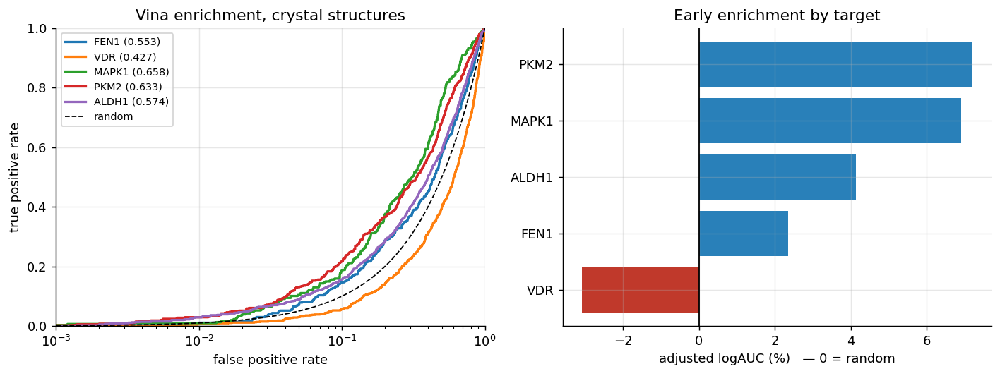

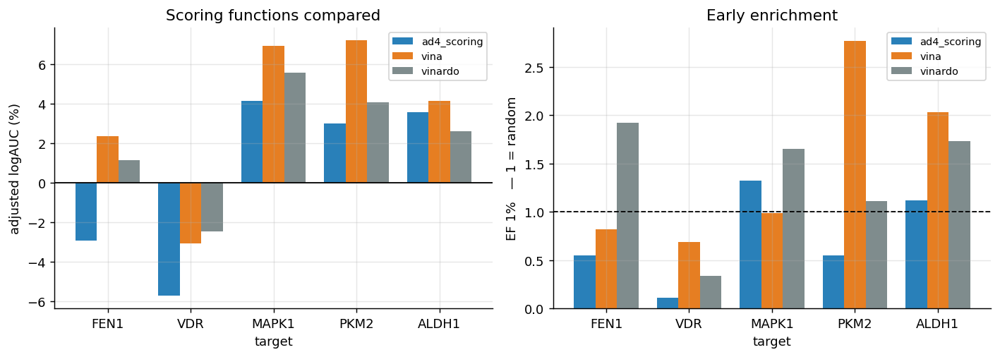

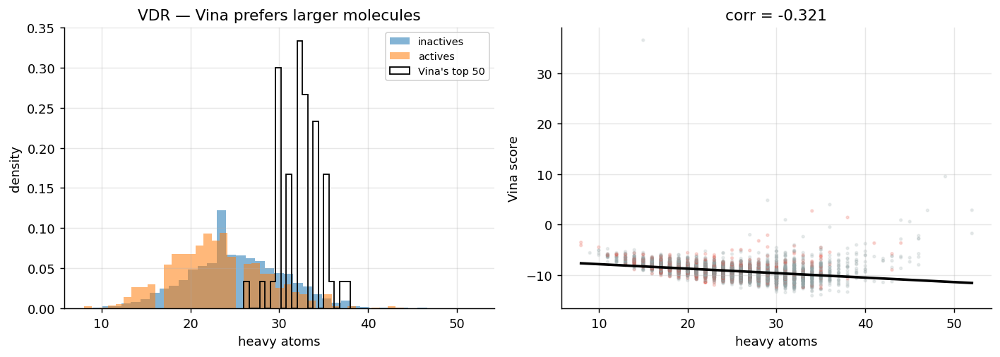

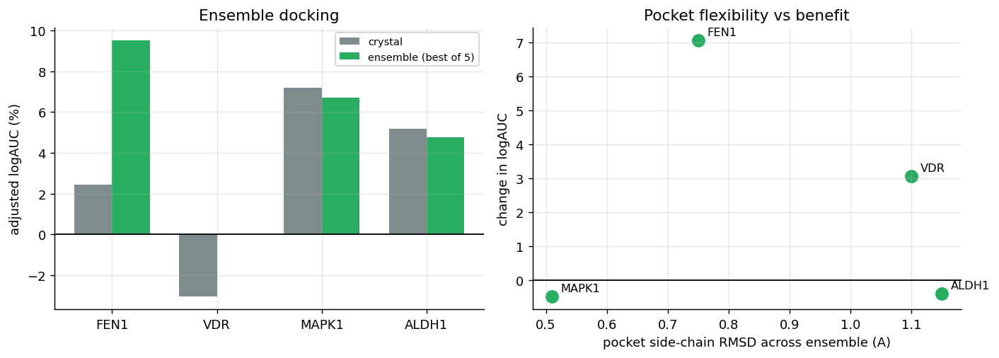

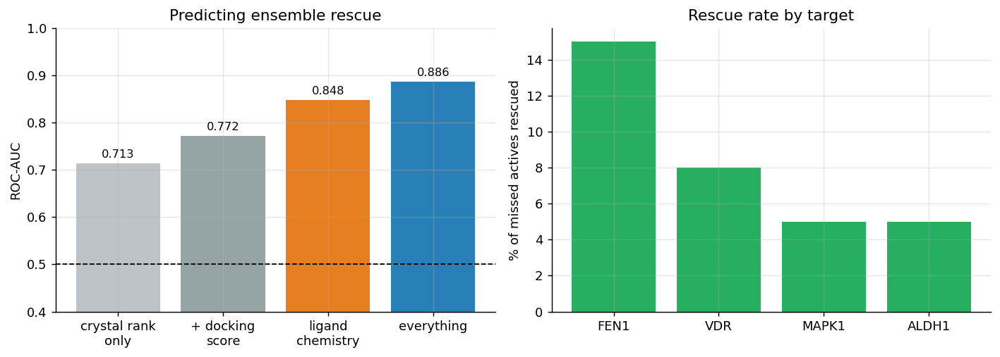

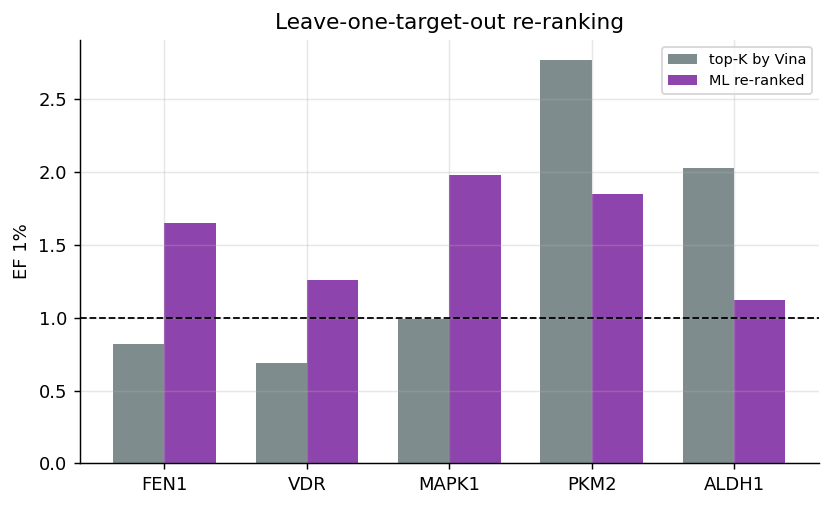

fig1_part1_enrichment.png
fig2_part2_scoring.png
fig3_size_bias.png
fig4_part3_ensemble.png
fig5_part3a_classifier.png
fig6_part3b_loocv.png


In [3]:
!pip -q install rdkit
from sklearn.metrics import roc_curve
plt.rcParams.update({'figure.dpi':130, 'font.size':10, 'axes.grid':True,
                     'grid.alpha':.3, 'axes.spines.top':False, 'axes.spines.right':False})

# ---- Fig 1: enrichment curves, all targets ------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11,4.2))
xr = np.logspace(-3,0,200)
for t in TARGETS:
    d = pd.read_csv(f'{RES}/{t}_vina_scores.csv', dtype={'mol_id':str})
    fpr, tpr, _ = roc_curve(d.label.values, -d.vina.values)
    a = p1.set_index('target').AUC[t]
    ax[0].plot(fpr, tpr, lw=1.8, label=f'{t} ({a:.3f})')
ax[0].plot(xr, xr, 'k--', lw=1, label='random')
ax[0].set_xscale('log'); ax[0].set_xlim(1e-3,1); ax[0].set_ylim(0,1)
ax[0].set_xlabel('false positive rate'); ax[0].set_ylabel('true positive rate')
ax[0].set_title('Vina enrichment, crystal structures'); ax[0].legend(fontsize=8)

o = p1.sort_values('logAUC')
c = ['#c0392b' if v < 0 else '#2980b9' for v in o.logAUC]
ax[1].barh(o.target, o.logAUC, color=c)
ax[1].axvline(0, color='k', lw=1)
ax[1].set_xlabel('adjusted logAUC (%)   — 0 = random')
ax[1].set_title('Early enrichment by target')
plt.tight_layout(); plt.savefig(f'{FIG}/fig1_part1_enrichment.png', bbox_inches='tight'); plt.show()

# ---- Fig 2: scoring-function comparison ---------------------------------
piv = p2.pivot(index='target', columns='scoring', values='logAUC').loc[TARGETS]
fig, ax = plt.subplots(1, 2, figsize=(11,4))
piv.plot.bar(ax=ax[0], width=.78, color=['#2980b9','#e67e22','#7f8c8d'])
ax[0].axhline(0, color='k', lw=1); ax[0].set_ylabel('adjusted logAUC (%)')
ax[0].set_title('Scoring functions compared'); ax[0].legend(fontsize=8); ax[0].tick_params(axis='x', rotation=0)

pv2 = p2.pivot(index='target', columns='scoring', values='EF1').loc[TARGETS]
pv2.plot.bar(ax=ax[1], width=.78, color=['#2980b9','#e67e22','#7f8c8d'])
ax[1].axhline(1, color='k', ls='--', lw=1)
ax[1].set_ylabel('EF 1%   — 1 = random'); ax[1].set_title('Early enrichment')
ax[1].legend(fontsize=8); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig(f'{FIG}/fig2_part2_scoring.png', bbox_inches='tight'); plt.show()

# ---- Fig 3: VDR size bias -----------------------------------------------
d = pd.read_csv(f'{RES}/VDR_all_scores.csv', dtype={'mol_id':str})
lig = pd.read_csv(f'{DRIVE}/VDR/ligands.csv', dtype={'mol_id':str})
from rdkit import Chem, RDLogger; RDLogger.DisableLog('rdApp.*')
lig['hac'] = [Chem.MolFromSmiles(s).GetNumHeavyAtoms() if Chem.MolFromSmiles(s) else np.nan
              for s in lig.smiles]
d = d.merge(lig[['mol_id','hac']], on='mol_id').dropna(subset=['hac'])

fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].hist(d[d.label==0].hac, bins=40, alpha=.55, density=True, label='inactives')
ax[0].hist(d[d.label==1].hac, bins=40, alpha=.55, density=True, label='actives')
ax[0].hist(d.nsmallest(50,'vina').hac, bins=20, histtype='step', lw=2.2,
           density=True, color='k', label="Vina's top 50")
ax[0].set_xlabel('heavy atoms'); ax[0].set_ylabel('density')
ax[0].set_title('VDR — Vina prefers larger molecules'); ax[0].legend(fontsize=8)

ax[1].scatter(d.hac, d.vina, s=4, alpha=.18, c=np.where(d.label==1,'#e74c3c','#95a5a6'))
z = np.polyfit(d.hac, d.vina, 1)
xs = np.linspace(d.hac.min(), d.hac.max(), 50)
ax[1].plot(xs, np.polyval(z, xs), 'k-', lw=2)
ax[1].set_xlabel('heavy atoms'); ax[1].set_ylabel('Vina score')
ax[1].set_title(f"corr = {d.vina.corr(d.hac):.3f}")
plt.tight_layout(); plt.savefig(f'{FIG}/fig3_size_bias.png', bbox_inches='tight'); plt.show()

# ---- Fig 4: crystal vs ensemble -----------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11,4))
x = np.arange(len(p3)); w = .36
ax[0].bar(x-w/2, p3.logAUC_xtal, w, label='crystal', color='#7f8c8d')
ax[0].bar(x+w/2, p3.logAUC_ens,  w, label='ensemble (best of 5)', color='#27ae60')
ax[0].set_xticks(x); ax[0].set_xticklabels(p3.target); ax[0].axhline(0,color='k',lw=1)
ax[0].set_ylabel('adjusted logAUC (%)'); ax[0].set_title('Ensemble docking'); ax[0].legend(fontsize=8)

rmsd = key['pocket_rmsd_mean']
dlog = (p3.logAUC_ens - p3.logAUC_xtal).values
ax[1].scatter([rmsd[t] for t in p3.target], dlog, s=90, c='#27ae60')
for t, dv in zip(p3.target, dlog):
    ax[1].annotate(t, (rmsd[t], dv), textcoords='offset points', xytext=(7,4), fontsize=9)
ax[1].axhline(0, color='k', lw=1)
ax[1].set_xlabel('pocket side-chain RMSD across ensemble (A)')
ax[1].set_ylabel('change in logAUC'); ax[1].set_title('Pocket flexibility vs benefit')
plt.tight_layout(); plt.savefig(f'{FIG}/fig4_part3_ensemble.png', bbox_inches='tight'); plt.show()

# ---- Fig 5: classifier ---------------------------------------------------
a = key['part3a']
fig, ax = plt.subplots(1, 2, figsize=(11,4))
labs = ['crystal rank\nonly','+ docking\nscore','ligand\nchemistry','everything']
vals = [a['auc_rank_only'], a['auc_docking_only'], a['auc_chemistry_only'], a['auc_all']]
ax[0].bar(labs, vals, color=['#bdc3c7','#95a5a6','#e67e22','#2980b9'])
ax[0].axhline(.5, color='k', ls='--', lw=1); ax[0].set_ylim(.4,1)
ax[0].set_ylabel('ROC-AUC'); ax[0].set_title('Predicting ensemble rescue')
for i, v in enumerate(vals): ax[0].text(i, v+.012, f'{v:.3f}', ha='center', fontsize=9)

rb = a['rescue_by_target']
ks = [t for t in TARGETS if t in rb]
ax[1].bar(ks, [100*rb[t] for t in ks], color='#27ae60')
ax[1].set_ylabel('% of missed actives rescued'); ax[1].set_title('Rescue rate by target')
plt.tight_layout(); plt.savefig(f'{FIG}/fig5_part3a_classifier.png', bbox_inches='tight'); plt.show()

# ---- Fig 6: Part 3b ------------------------------------------------------
d1 = p3b[p3b.pct=='1%']
fig, ax = plt.subplots(figsize=(6.5,4))
x = np.arange(len(d1)); w=.36
ax.bar(x-w/2, d1.EF_vina, w, label='top-K by Vina', color='#7f8c8d')
ax.bar(x+w/2, d1.EF_ML,   w, label='ML re-ranked', color='#8e44ad')
ax.axhline(1, color='k', ls='--', lw=1)
ax.set_xticks(x); ax.set_xticklabels(d1.target); ax.set_ylabel('EF 1%')
ax.set_title('Leave-one-target-out re-ranking'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/fig6_part3b_loocv.png', bbox_inches='tight'); plt.show()

print('\n'.join(sorted(os.listdir(FIG))))

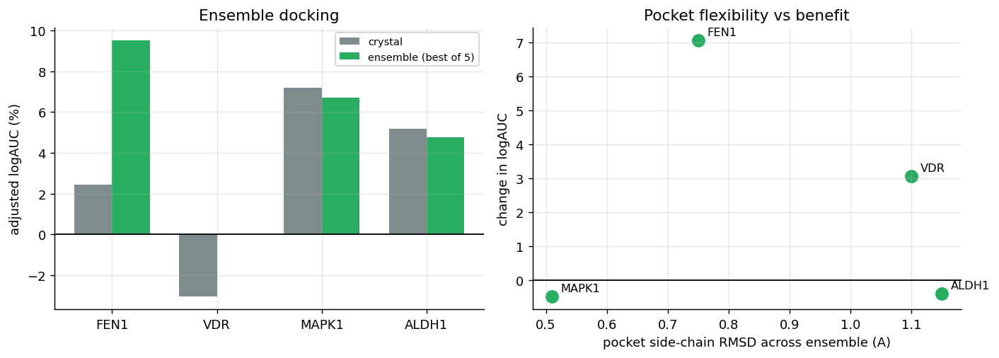

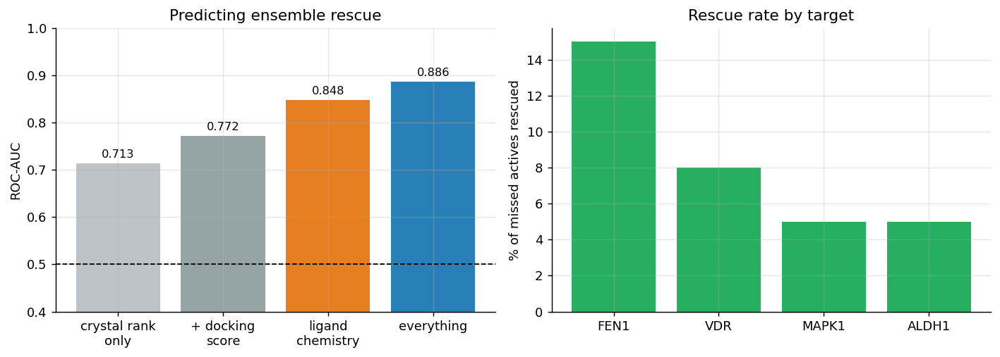

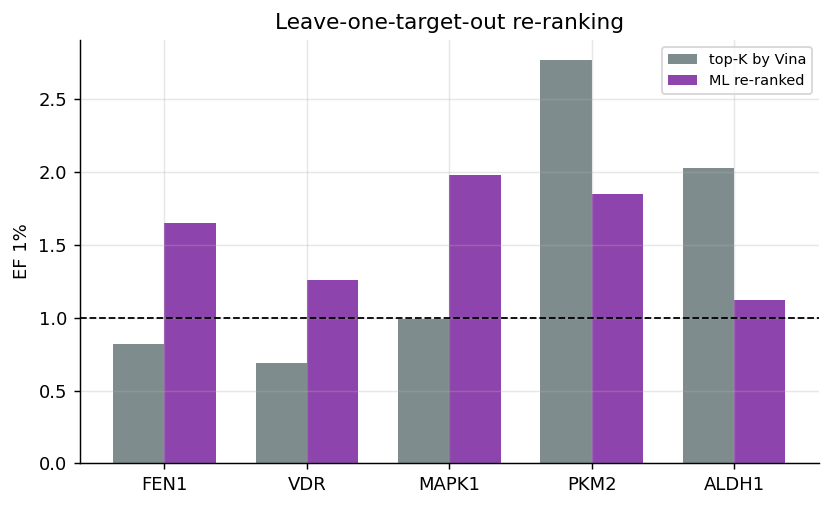

fig1_part1_enrichment.png
fig2_part2_scoring.png
fig3_size_bias.png
fig4_part3_ensemble.png
fig5_part3a_classifier.png
fig6_part3b_loocv.png


In [4]:
# ---- Fig 4: crystal vs ensemble -----------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11,4))
x = np.arange(len(p3)); w = .36
ax[0].bar(x-w/2, p3.logAUC_xtal, w, label='crystal', color='#7f8c8d')
ax[0].bar(x+w/2, p3.logAUC_ens,  w, label='ensemble (best of 5)', color='#27ae60')
ax[0].set_xticks(x); ax[0].set_xticklabels(p3.target); ax[0].axhline(0,color='k',lw=1)
ax[0].set_ylabel('adjusted logAUC (%)'); ax[0].set_title('Ensemble docking'); ax[0].legend(fontsize=8)

rmsd = key['pocket_rmsd_mean']
dlog = (p3.logAUC_ens - p3.logAUC_xtal).values
ax[1].scatter([rmsd[t] for t in p3.target], dlog, s=90, c='#27ae60')
for t, dv in zip(p3.target, dlog):
    ax[1].annotate(t, (rmsd[t], dv), textcoords='offset points', xytext=(7,4), fontsize=9)
ax[1].axhline(0, color='k', lw=1)
ax[1].set_xlabel('pocket side-chain RMSD across ensemble (A)')
ax[1].set_ylabel('change in logAUC'); ax[1].set_title('Pocket flexibility vs benefit')
plt.tight_layout(); plt.savefig(f'{FIG}/fig4_part3_ensemble.png', bbox_inches='tight'); plt.show()

# ---- Fig 5: classifier ---------------------------------------------------
a = key['part3a']
fig, ax = plt.subplots(1, 2, figsize=(11,4))
labs = ['crystal rank\nonly','+ docking\nscore','ligand\nchemistry','everything']
vals = [a['auc_rank_only'], a['auc_docking_only'], a['auc_chemistry_only'], a['auc_all']]
ax[0].bar(labs, vals, color=['#bdc3c7','#95a5a6','#e67e22','#2980b9'])
ax[0].axhline(.5, color='k', ls='--', lw=1); ax[0].set_ylim(.4,1)
ax[0].set_ylabel('ROC-AUC'); ax[0].set_title('Predicting ensemble rescue')
for i, v in enumerate(vals): ax[0].text(i, v+.012, f'{v:.3f}', ha='center', fontsize=9)

rb = a['rescue_by_target']; ks = [t for t in TARGETS if t in rb]
ax[1].bar(ks, [100*rb[t] for t in ks], color='#27ae60')
ax[1].set_ylabel('% of missed actives rescued'); ax[1].set_title('Rescue rate by target')
plt.tight_layout(); plt.savefig(f'{FIG}/fig5_part3a_classifier.png', bbox_inches='tight'); plt.show()

# ---- Fig 6: Part 3b ------------------------------------------------------
d1 = p3b[p3b.pct=='1%']
fig, ax = plt.subplots(figsize=(6.5,4))
x = np.arange(len(d1)); w=.36
ax.bar(x-w/2, d1.EF_vina, w, label='top-K by Vina', color='#7f8c8d')
ax.bar(x+w/2, d1.EF_ML,   w, label='ML re-ranked', color='#8e44ad')
ax.axhline(1, color='k', ls='--', lw=1)
ax.set_xticks(x); ax.set_xticklabels(d1.target); ax.set_ylabel('EF 1%')
ax.set_title('Leave-one-target-out re-ranking'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/fig6_part3b_loocv.png', bbox_inches='tight'); plt.show()

print('\n'.join(sorted(os.listdir(FIG))))

In [2]:
import pandas as pd
from google.colab import drive; drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/docking_project'

cmp = pd.read_csv(f'{DRIVE}/RESULTS/part2_scoring_comparison.csv')
print('logAUC'); print(cmp.pivot(index='target', columns='scoring', values='logAUC').to_string())
print('\nEF1%');  print(cmp.pivot(index='target', columns='scoring', values='EF1').to_string())
print('\nAUC');   print(cmp.pivot(index='target', columns='scoring', values='AUC').to_string())

Mounted at /content/drive
logAUC
scoring  ad4_scoring  vina  vinardo
target                             
ALDH1           3.55  4.13     2.61
FEN1           -2.94  2.35     1.12
MAPK1           4.13  6.92     5.56
PKM2            3.00  7.20     4.07
VDR            -5.71 -3.08    -2.48

EF1%
scoring  ad4_scoring  vina  vinardo
target                             
ALDH1           1.12  2.03     1.73
FEN1            0.55  0.82     1.92
MAPK1           1.32  0.99     1.65
PKM2            0.55  2.77     1.11
VDR             0.11  0.69     0.34

AUC
scoring  ad4_scoring   vina  vinardo
target                              
ALDH1          0.571  0.574    0.547
FEN1           0.415  0.553    0.491
MAPK1          0.600  0.658    0.623
PKM2           0.596  0.633    0.599
VDR            0.370  0.427    0.451
